# NumPy untuk Analisis Data: Dasar, Seleksi, Pembaruan, dan Transformasi Array
**Muhammad Haris Faulidi**

**Capaian Pembelajaran Mata Kuliah (CPMK)**
CPMK 3. Mampu mengolah dan menganalisis data menggunakan paket perangkat lunak yang tersedia.

**Petunjuk penggunaan notebook**
1. Jalankan sel kode **secara berurutan dari atas ke bawah** (`Shift + Enter`).
2. Sebelum menjalankan sebuah sel, baca penjelasannya lalu **coba tebak keluarannya**. Setelah dijalankan, bandingkan tebakan Anda dengan hasil sebenarnya.
3. Kerjakan **latihan mandiri** di akhir setiap bagian sebelum melihat kunci jawaban (jika tersedia).
4. Setiap bagian diawali dengan `import numpy as np` sehingga bagian tersebut juga dapat dijalankan secara terpisah.

## Daftar Isi

| Bagian | Topik | Fungsi / konsep utama |
|---|---|---|
| **Bagian I** | Pengantar NumPy & Seleksi Array Dasar | `np.array()`, `.ndim`, `.shape`, `.size`, `.dtype`, `np.zeros()`, `np.random.random()`, `np.arange()`, `.astype()`, `.reshape()`, `.flatten()`, indexing & slicing |
| **Bagian II** | Seleksi & Pembaruan Array serta Matematika Array Dasar | `np.sort()`, `np.argsort()`, Boolean mask, fancy indexing, `np.where()`, `np.concatenate()`, `np.delete()`, `np.sum()`, `np.min()`, `np.max()`, `np.mean()`, `np.cumsum()`, `keepdims`, vektorisasi |
| **Bagian III** | Matematika Array Lanjutan & Transformasi Array | broadcasting, `np.broadcast_shapes()`, `np.save()`, `np.load()`, array gambar RGB/RGBA, `np.clip()`, `np.flip()`, `.T`, `np.transpose()`, `np.swapaxes()`, `np.split()`, `np.array_split()`, `np.stack()` |

> **Cara membaca penomoran:** angka pertama menunjukkan bagian. Contoh: **2.3.4** berarti Bagian II, Subbab 3, Sub-subbab 4.

---
# BAGIAN I — Pengantar NumPy & Seleksi Array Dasar

**Yang akan dipelajari:**
`np.array()` · `type()` · `.ndim` · `.shape` · `.size` · `.dtype` · `np.zeros()` · `np.random.random()` · `np.arange()` · `.astype()` · `.reshape()` · `.flatten()` · indexing · slicing

**Setelah menyelesaikan bagian ini, Anda diharapkan mampu:**
- membuat array NumPy 1D sampai 4D dan menjelaskan strukturnya;
- membaca atribut array (`ndim`, `shape`, `size`, `dtype`);
- mengonversi tipe data dan memahami *type coercion*;
- mengubah bentuk array dengan `reshape()` dan `flatten()`;
- mengambil elemen, baris, kolom, dan sub-matriks dengan indexing dan slicing.

---
## 1.1 Pengenalan NumPy

### 1.1.1 Apa itu NumPy?

**NumPy** (*Numerical Python*) adalah pustaka Python untuk komputasi numerik dan ilmiah. Objek utamanya adalah **`ndarray`** (*N-dimensional array*), yaitu wadah data berukuran tetap yang seluruh elemennya bertipe sama.

Mengapa NumPy penting dalam statistika dan sains data?
- **Cepat** — operasi dijalankan oleh kode C yang sudah dioptimalkan, bukan perulangan Python satu per satu.
- **Ringkas** — satu baris operasi dapat langsung diterapkan pada seluruh elemen array.
- **Fondasi ekosistem** — pustaka seperti pandas, SciPy, scikit-learn, dan matplotlib dibangun di atas NumPy.

### 1.1.2 Mengimpor NumPy

NumPy diimpor dengan alias konvensional **`np`**, sehingga cukup menulis `np.array()` alih-alih `numpy.array()`.

Jika NumPy belum terpasang, hapus tanda `#` pada sel di bawah lalu jalankan sekali.

In [1]:
# Install Numpy (jika belum hapus # dibawah)
# %pip install numpy

In [2]:
import numpy as np
print("NumPy version:", np.__version__)

NumPy version: 2.5.4


### 1.1.3 List Python vs. Array NumPy

| Aspek | List Python | Array NumPy |
|---|---|---|
| Tipe elemen | Boleh campuran (angka, teks, dll.) | Satu tipe yang sama untuk semua elemen |
| Operator `+` | **Menggabungkan** (menyambung) dua list | **Menjumlahkan** elemen pada posisi yang bersesuaian |
| Kecepatan perhitungan | Relatif lambat untuk data besar | Cepat dan hemat memori |

Jalankan dua sel berikut dan perhatikan perbedaan tipe objek serta hasil operator `+`.

In [3]:
python_list = [2, 4, 6]
numpy_array = np.array([2, 4, 6])

print("Python list:", python_list)
print("NumPy array:", numpy_array)
print("Python type:", type(python_list))
print("NumPy type:", type(numpy_array))

Python list: [2, 4, 6]
NumPy array: [2 4 6]
Python type: <class 'list'>
NumPy type: <class 'numpy.ndarray'>


In [4]:
print(python_list + python_list)
print(numpy_array + numpy_array)

[2, 4, 6, 2, 4, 6]
[ 4  8 12]


**Interpretasi:** `python_list + python_list` menghasilkan list sepanjang 6 elemen (disambung), sedangkan `numpy_array + numpy_array` menghasilkan `[4 8 12]` karena setiap elemen dijumlahkan dengan pasangannya.

---
## 1.2 Membuat Array NumPy

### 1.2.1 Membuat Array dari List Python

Fungsi `np.array()` mengubah list (atau list bersarang) Python menjadi array NumPy. **Banyaknya tingkat kurung siku** menentukan jumlah dimensi:

| Dimensi | Contoh struktur | Gambaran |
|---|---|---|
| **1D** | `[1, 2, 3]` | Vektor (satu baris data) |
| **2D** | `[[1, 2], [3, 4]]` | Matriks (baris × kolom) |
| **3D** | `[[[...]], [[...]]]` | Tumpukan beberapa matriks |
| **4D** | `[[[[...]]]]` | Kumpulan beberapa array 3D |

Setiap baris pada tingkat yang sama **harus memiliki panjang yang sama** agar array berbentuk teratur.

**Shape** adalah tuple yang menunjukkan banyaknya elemen pada setiap dimensi, misalnya `(3, 4)` berarti 3 baris dan 4 kolom.

### 1.2.2 Array Satu Dimensi (1D)

Array 1D cocok untuk menyimpan pengamatan dari **satu variabel**, misalnya nilai lima mahasiswa.

In [5]:
student_scores = [75, 80, 92, 86, 88]
scores_1d = np.array(student_scores)

print(scores_1d)
print("Dimensions:", scores_1d.ndim)
print("Shape:", scores_1d.shape)

[75 80 92 86 88]
Dimensions: 1
Shape: (5,)


**Interpretasi:** `ndim = 1` (satu sumbu) dan `shape = (5,)`. Tanda koma pada `(5,)` menandakan tuple dengan satu anggota — artinya ada 5 elemen pada satu sumbu.

### 1.2.3 Array Dua Dimensi (2D)

Array 2D menyimpan data dalam bentuk **baris dan kolom**, seperti tabel. Pada contoh berikut, **setiap baris mewakili satu mahasiswa** dan **setiap kolom mewakili satu jenis penilaian**.

In [6]:
student_assessments = [[80, 85, 90],
                       [75, 88, 84],
                       [92, 90, 95]]

scores_2d = np.array(student_assessments)

print(scores_2d)
print("Dimensions:", scores_2d.ndim)
print("Shape:", scores_2d.shape)

[[80 85 90]
 [75 88 84]
 [92 90 95]]
Dimensions: 2
Shape: (3, 3)


**Interpretasi:** shape `(3, 3)` berarti **3 baris** (mahasiswa) dan **3 kolom** (penilaian).

### 1.2.4 Array Tiga Dimensi (3D)

Array 3D dapat dibayangkan sebagai **tumpukan matriks**. Contoh di bawah menumpuk data pengamatan minggu ke-1 dan minggu ke-2, masing-masing berupa matriks 2 × 2.

In [7]:
week_1 = np.array([[10, 12],
                   [14, 16]])
week_2 = np.array([[11, 13],
                   [15, 17]])

observations_3d = np.array([week_1, week_2])

print(observations_3d)
print("Dimensions:", observations_3d.ndim)
print("Shape:", observations_3d.shape)

[[[10 12]
  [14 16]]

 [[11 13]
  [15 17]]]
Dimensions: 3
Shape: (2, 2, 2)


**Interpretasi:** shape `(2, 2, 2)` dibaca sebagai **2 matriks**, masing-masing **2 baris** dan **2 kolom**. Sumbu pertama (`axis=0`) menentukan matriks mana yang dipilih (minggu ke-1 atau ke-2).

### 1.2.5 Array Empat Dimensi (4D)

Array 4D menambahkan satu tingkat organisasi lagi: **kumpulan beberapa array 3D**. Struktur seperti ini muncul pada data ilmiah, misalnya kumpulan (*batch*) gambar atau pengamatan multidimensi.

In [8]:
first_cube = np.array([[[1, 2], [3, 4]],
                       [[5, 6], [7, 8]]])
second_cube = np.array([[[11, 12], [13, 14]],
                        [[15, 16], [17, 18]]])

observations_4d = np.array([first_cube, second_cube])

print(observations_4d)
print("Dimensions:", observations_4d.ndim)
print("Shape:", observations_4d.shape)

[[[[ 1  2]
   [ 3  4]]

  [[ 5  6]
   [ 7  8]]]


 [[[11 12]
   [13 14]]

  [[15 16]
   [17 18]]]]
Dimensions: 4
Shape: (2, 2, 2, 2)


**Interpretasi:** shape `(2, 2, 2, 2)` berarti 2 "kubus", masing-masing berisi 2 matriks berukuran 2 × 2.

### 1.2.6 Membuat Array dari Nol: `np.zeros()`

`np.zeros(shape)` membuat array yang seluruh elemennya bernilai **0** (bertipe `float64` secara default). Fungsi ini berguna sebagai wadah awal sebelum diisi nilai lain.
- `np.zeros(5)` → vektor berisi 5 angka nol.
- `np.zeros((3, 4))` → matriks 3 × 4. Perhatikan **dua tanda kurung**: shape untuk array multidimensi ditulis sebagai tuple.

In [9]:
zero_vector = np.zeros(5)
zero_matrix = np.zeros((3, 4))

print("1D zeros:")
print(zero_vector)
print("2D zeros:")
print(zero_matrix)

1D zeros:
[0. 0. 0. 0. 0.]
2D zeros:
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]


### 1.2.7 Membuat Array Acak: `np.random.random()`

`np.random.random(shape)` menghasilkan bilangan desimal acak pada rentang **0 sampai kurang dari 1** (`[0, 1)`).

`np.random.seed(42)` mengatur **titik awal pembangkit bilangan acak**, sehingga hasil acaknya **selalu sama** setiap kali kode dijalankan. Hal ini penting agar hasil analisis dapat direproduksi (*reproducible*).

In [10]:
np.random.seed(42)
random_measurements = np.random.random((2, 3))

print(random_measurements)
print("Shape:", random_measurements.shape)

[[0.37454012 0.95071431 0.73199394]
 [0.59865848 0.15601864 0.15599452]]
Shape: (2, 3)


### 1.2.8 Membuat Deret Angka: `np.arange()`

Format umum: `np.arange(start, stop, step)`
- `start` — nilai awal (**ikut** disertakan). Default `0`.
- `stop` — batas akhir (**tidak** disertakan).
- `step` — selisih antar-angka. Default `1`.

Contoh: `np.arange(2, 11, 2)` → `[2 4 6 8 10]`; angka 11 tidak pernah dicapai.

In [11]:
sequence_a = np.arange(5)
sequence_b = np.arange(2, 11, 2)
sequence_c = np.arange(-3, 4, 3)

print("Default sequence:", sequence_a)
print("Even-number sequence:", sequence_b)
print("Stepped sequence:", sequence_c)

Default sequence: [0 1 2 3 4]
Even-number sequence: [ 2  4  6  8 10]
Stepped sequence: [-3  0  3]


---
## 1.3 Atribut dan Tipe Data Array

### 1.3.1 Dimensi dan Sumbu (*Axis*)

**Axis** (sumbu) adalah arah dimensi pada array. Penomoran sumbu dimulai dari 0:
- Pada array 2D: `axis=0` = arah **baris** (bergerak ke bawah), `axis=1` = arah **kolom** (bergerak ke kanan).
- Pada array 3D: `axis=0` = lapisan/matriks, `axis=1` = baris, `axis=2` = kolom.

Empat atribut dasar yang wajib diperiksa:

| Atribut | Arti | Contoh hasil |
|---|---|---|
| `.ndim` | Jumlah dimensi/sumbu | `2` |
| `.shape` | Panjang array pada setiap sumbu | `(3, 4)` |
| `.size` | Jumlah seluruh elemen | `12` |
| `.dtype` | Tipe data elemen | `int64`, `float64`, dll. |

> Atribut ditulis **tanpa tanda kurung** (`arr.shape`, bukan `arr.shape()`), karena ia adalah properti, bukan fungsi.

In [12]:
measurement_matrix = np.array([[12, 15, 18, 21],
                               [14, 16, 20, 22],
                               [11, 13, 17, 19]])

print("Array:")
print(measurement_matrix)
print("ndim:", measurement_matrix.ndim)
print("shape:", measurement_matrix.shape)
print("size:", measurement_matrix.size)
print("dtype:", measurement_matrix.dtype)

Array:
[[12 15 18 21]
 [14 16 20 22]
 [11 13 17 19]]
ndim: 2
shape: (3, 4)
size: 12
dtype: int64


### 1.3.2 Memahami Shape dan Size

Shape `(3, 4)` berarti 3 baris dan 4 kolom, sehingga size = `3 × 4 = 12` elemen. Untuk array 3D atau 4D, **size adalah hasil kali seluruh angka pada shape**. Contoh: shape `(2, 2, 2, 2)` → size = 16.

Sel berikut membandingkan ketiga atribut untuk array 1D–4D yang telah dibuat sebelumnya.

In [13]:
print("1D:", scores_1d.ndim, scores_1d.shape, scores_1d.size)
print("2D:", scores_2d.ndim, scores_2d.shape, scores_2d.size)
print("3D:", observations_3d.ndim, observations_3d.shape, observations_3d.size)
print("4D:", observations_4d.ndim, observations_4d.shape, observations_4d.size)

1D: 1 (5,) 5
2D: 2 (3, 3) 9
3D: 3 (2, 2, 2) 8
4D: 4 (2, 2, 2, 2) 16


### 1.3.3 Tipe Data Umum NumPy (`dtype`)

| Jenis | Contoh `dtype` | Keterangan |
|---|---|---|
| Bilangan bulat | `int32`, `int64` | Angka tanpa desimal |
| Bilangan desimal | `float32`, `float64` | Angka pecahan |
| Boolean | `bool` | `True` / `False` |
| Teks | `<U6`, dll. | `U` = Unicode, angka = panjang maksimum karakter |

Angka di belakang nama tipe (misalnya `64`) menunjukkan **jumlah bit** yang dipakai untuk menyimpan setiap nilai. Karena semua elemen array harus bertipe sama, mencampur jenis nilai dapat memicu **konversi tipe otomatis** (dibahas di 1.3.6).

In [14]:
integer_values = np.array([1, 2, 3])
float_values = np.array([1.5, 2.5, 3.5])
boolean_values = np.array([True, False, True])
string_values = np.array(["low", "medium", "high"])

print("Integer:", integer_values.dtype)
print("Float:", float_values.dtype)
print("Boolean:", boolean_values.dtype)
print("String:", string_values.dtype)

Integer: int64
Float: float64
Boolean: bool
String: <U6


### 1.3.4 Menentukan Tipe Data Secara Eksplisit

Gunakan argumen `dtype` di dalam `np.array()` untuk meminta tipe tertentu. Tipe yang lebih kecil (misalnya `float32`) **lebih hemat memori**, tetapi rentang nilai dan presisinya lebih terbatas.

In [15]:
measurements_float32 = np.array([1.25, 2.75, 3.50], dtype=np.float32)
counts_int32 = np.array([10, 20, 30], dtype=np.int32)

print(measurements_float32, measurements_float32.dtype)
print(counts_int32, counts_int32.dtype)

[1.25 2.75 3.5 ] float32
[10 20 30] int32


**Perhatikan sel berikut:** angka desimal `[1.25, 2.75, 3.50]` dipaksa menjadi `int32`. Tebak dulu hasilnya sebelum menjalankan sel!

In [16]:
measurements_int32 = np.array([1.25, 2.75, 3.50], dtype=np.int32)
measurements_int32 

array([1, 2, 3], dtype=int32)

**Interpretasi:** hasilnya `[1, 2, 3]` — bagian desimal **dipotong (dibuang)**, bukan dibulatkan. Nilai `2.75` menjadi `2`, bukan `3`.

### 1.3.5 Konversi Tipe dengan `.astype()`

`.astype(tipe_baru)` menghasilkan **array baru** dengan tipe data yang diminta; array asli tidak berubah. Penerapan umum: mengubah teks berisi angka (misalnya hasil membaca file) menjadi tipe numerik agar bisa dihitung.

> ⚠️ Mengubah `float` menjadi `int` **memotong** bagian desimal (*truncation*), bukan membulatkan ke bilangan bulat terdekat. Jika ingin pembulatan, gunakan `np.round()` terlebih dahulu.

In [17]:
text_scores = np.array(["70", "85", "90"])
numeric_scores = text_scores.astype(np.int64)

print("Before:", text_scores, text_scores.dtype)
print("After:", numeric_scores, numeric_scores.dtype)

Before: ['70' '85' '90'] <U2
After: [70 85 90] int64


In [18]:
continuous_values = np.array([1.9, 2.1, 3.8])
integer_conversion = continuous_values.astype(int)

print("Original:", continuous_values)
print("Converted:", integer_conversion)

Original: [1.9 2.1 3.8]
Converted: [1 2 3]


**Interpretasi:** `1.9 → 1`, `2.1 → 2`, `3.8 → 3`. Semua desimal dibuang.

### 1.3.6 *Type Coercion* (Konversi Tipe Otomatis)

**Type coercion** terjadi ketika NumPy secara otomatis memilih **satu tipe bersama** untuk semua elemen. Urutan "naik tingkat" yang umum:

`bool` → `int` → `float` → `str`

Artinya:
- campuran `int` dan `float` → semua menjadi `float`;
- campuran `bool` dan `int` → `True` menjadi `1`, `False` menjadi `0`;
- campuran angka dan teks → semua menjadi **teks** (sehingga tidak bisa dihitung lagi!).

> 💡 **Kebiasaan baik:** selalu periksa `.dtype` sebelum melakukan analisis numerik.

In [19]:
coercion_a = np.array([10, 20.5, 30])
coercion_b = np.array([True, False, 5])
coercion_c = np.array([1, "two", 3])

print(coercion_a, coercion_a.dtype)
print(coercion_b, coercion_b.dtype)
print(coercion_c, coercion_c.dtype)

[10.  20.5 30. ] float64
[1 0 5] int64
['1' 'two' '3'] <U21


---
## 1.4 Mengubah Bentuk Array (*Reshaping*)

### 1.4.1 Memahami Shape Array

Shape menggambarkan **cara elemen disusun**, bukan isinya. Tiga array berikut berisi enam angka yang sama, tetapi bentuknya berbeda:

| Shape | Jenis | Keterangan |
|---|---|---|
| `(6,)` | 1D | Vektor biasa, hanya satu sumbu |
| `(1, 6)` | 2D | Satu **baris**, enam kolom |
| `(6, 1)` | 2D | Enam baris, satu **kolom** |

Perbedaan ini sangat penting saat menggabungkan array atau menggunakan broadcasting (Bagian II dan III).

In [20]:
base_values = np.arange(1, 7)

row_array = base_values.reshape(1, 6)
column_array = base_values.reshape(6, 1)

print("1D shape:", base_values.shape)
print("Row shape:", row_array.shape)
print(row_array)
print("Column shape:", column_array.shape)
print(column_array)

1D shape: (6,)
Row shape: (1, 6)
[[1 2 3 4 5 6]]
Column shape: (6, 1)
[[1]
 [2]
 [3]
 [4]
 [5]
 [6]]


### 1.4.2 Mengubah Bentuk dengan `.reshape()`

`.reshape(bentuk_baru)` menyusun ulang elemen **tanpa mengubah jumlah elemen**. Array berisi 12 angka dapat diubah menjadi `(3, 4)`, `(4, 3)`, atau `(2, 2, 3)`, karena semua bentuk itu memiliki tepat 12 posisi.

NumPy mengisi bentuk baru dengan membaca elemen **sesuai urutan aslinya, baris demi baris** (dari kiri ke kanan, lalu turun ke baris berikutnya).

In [21]:
values_12 = np.arange(1, 13)

matrix_3x4 = values_12.reshape(3, 4)
matrix_4x3 = values_12.reshape(4, 3)
array_2x2x3 = values_12.reshape(2, 2, 3)

print("Original:", values_12)
print("3 × 4:")
print(matrix_3x4)
print("4 × 3:")
print(matrix_4x3)
print("2 × 2 × 3:")
print(array_2x2x3)

Original: [ 1  2  3  4  5  6  7  8  9 10 11 12]
3 × 4:
[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
4 × 3:
[[ 1  2  3]
 [ 4  5  6]
 [ 7  8  9]
 [10 11 12]]
2 × 2 × 3:
[[[ 1  2  3]
  [ 4  5  6]]

 [[ 7  8  9]
  [10 11 12]]]


### 1.4.3 Syarat Kompatibilitas `reshape()`

**Hasil kali angka-angka pada shape baru harus sama dengan size array.**
- Size 12 → `(3, 4)` ✅ karena 3 × 4 = 12.
- Size 12 → `(5, 3)` ❌ karena 5 × 3 = 15 → muncul `ValueError`.

Anda dapat menulis **`-1`** pada **satu** dimensi agar NumPy menghitung ukurannya secara otomatis. Contoh: `reshape(3, -1)` pada 12 elemen → NumPy menghitung 12 ÷ 3 = 4, sehingga hasilnya `(3, 4)`.

In [22]:
reshaped_automatically = values_12.reshape(3, -1)

print(reshaped_automatically)
print("Inferred shape:", reshaped_automatically.shape)

[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
Inferred shape: (3, 4)


### 1.4.4 Meratakan Array dengan `.flatten()`

`.flatten()` mengubah array multidimensi menjadi **salinan baru berbentuk 1D**. Fungsi ini berguna saat analisis membutuhkan semua elemen dalam satu deret. Karena hasilnya salinan, mengubah hasil `flatten()` tidak akan mengubah array asli.

In [23]:
original_matrix = np.array([[1, 2],
                            [5, 7],
                            [6, 6]])
flattened_values = original_matrix.flatten()

print("Original:")
print(original_matrix)
print("Flattened:")
print(flattened_values)
print("Flattened shape:", flattened_values.shape)

Original:
[[1 2]
 [5 7]
 [6 6]]
Flattened:
[1 2 5 7 6 6]
Flattened shape: (6,)


### 1.4.5 Perbandingan `reshape()` dan `flatten()`

| Operasi | Kegunaan utama | Jumlah dimensi hasil |
|---|---|---|
| `reshape(bentuk_baru)` | Menyusun ulang elemen ke bentuk yang dipilih | Sesuai `bentuk_baru` |
| `flatten()` | Mengubah semua elemen menjadi array 1D baru | Selalu 1D |

---
## 1.5 Indexing dan Slicing Dasar

### 1.5.1 Indexing Array 1D

**Indexing** mengambil **satu elemen** berdasarkan posisinya. Python memakai **indeks berbasis nol** (*zero-based*):

| Elemen ke- | 1 | 2 | 3 | 4 | 5 |
|---|---|---|---|---|---|
| Indeks positif | 0 | 1 | 2 | 3 | 4 |
| Indeks negatif | -5 | -4 | -3 | -2 | -1 |

Indeks negatif menghitung mundur dari akhir: `-1` adalah elemen terakhir.

In [24]:
values = np.array([2, 4, 6, 8, 10])

print("First element:", values[0])
print("Fourth element:", values[3])
print("Last element:", values[-1])

First element: 2
Fourth element: 8
Last element: 10


### 1.5.2 Indexing Array 2D

Untuk mengambil satu elemen pada array 2D diperlukan **indeks baris dan indeks kolom**: `array[baris, kolom]`. Keduanya dimulai dari 0.

Contoh: `marks[1, 2]` → baris ke-2 (indeks 1), kolom ke-3 (indeks 2).

In [25]:
marks = np.array([[80, 85, 90],
                  [75, 88, 84],
                  [92, 90, 95]])

print(marks)
print("Row 1, column 2:", marks[1, 2])
print("Row 2, column 0:", marks[2, 0])

[[80 85 90]
 [75 88 84]
 [92 90 95]]
Row 1, column 2: 84
Row 2, column 0: 92


### 1.5.3 Memilih Baris dan Kolom Utuh

- `array[i]` atau `array[i, :]` → seluruh **baris** ke-`i`.
- `array[:, j]` → seluruh **kolom** ke-`j`.

Tanda titik dua `:` berarti **"ambil semua posisi"** pada sumbu tersebut.

In [26]:
print("First row:", marks[0])
print("Second row:", marks[1, :])
print("Third column:", marks[:, 2])
print("First column:", marks[:, 0])

First row: [80 85 90]
Second row: [75 88 84]
Third column: [90 84 95]
First column: [80 75 92]


### 1.5.4 Slicing Array 1D

**Slicing** mengambil **beberapa elemen berurutan** dengan sintaks `array[start:stop]`:
- `start` **disertakan**;
- `stop` **tidak disertakan**;
- jika `start` dikosongkan → mulai dari awal array;
- jika `stop` dikosongkan → sampai akhir array.

Trik mengingat: banyaknya elemen hasil slicing = `stop - start`. Contoh: `sequence[1:4]` mengambil 4 − 1 = 3 elemen (indeks 1, 2, 3).

In [27]:
sequence = np.array([10, 20, 30, 40, 50, 60])

print("Positions 1 to 3:", sequence[1:4])
print("First three:", sequence[:3])
print("From position 3 onward:", sequence[3:])
print("All elements:", sequence[:])

Positions 1 to 3: [20 30 40]
First three: [10 20 30]
From position 3 onward: [40 50 60]
All elements: [10 20 30 40 50 60]


### 1.5.5 Slicing Array 2D

Slicing 2D menentukan rentang baris **dan** rentang kolom sekaligus:

`array[baris_awal:baris_akhir, kolom_awal:kolom_akhir]`

Cara ini digunakan untuk mengambil **sub-matriks**. Pada contoh berikut, `number_grid[1:4, 2:5]` mengambil baris indeks 1–3 dan kolom indeks 2–4.

In [28]:
number_grid = np.arange(1, 26).reshape(5, 5)

print("Original matrix:")
print(number_grid)
print("Rows 1–3, columns 2–4:")
print(number_grid[1:4, 2:5])

Original matrix:
[[ 1  2  3  4  5]
 [ 6  7  8  9 10]
 [11 12 13 14 15]
 [16 17 18 19 20]
 [21 22 23 24 25]]
Rows 1–3, columns 2–4:
[[ 8  9 10]
 [13 14 15]
 [18 19 20]]


### 1.5.6 Slicing dengan Langkah (*Step*)

Slicing dapat memiliki argumen ketiga: `array[start:stop:step]`. `step` menentukan jarak antarposisi yang diambil.

| Sintaks | Arti |
|---|---|
| `::2` | Ambil setiap elemen kedua, mulai dari indeks 0 |
| `1::2` | Ambil setiap elemen kedua, mulai dari indeks 1 |
| `::-1` | Membalik urutan array |

Step juga dapat diterapkan secara terpisah pada baris dan kolom array 2D, misalnya `grid[::2, ::2]`.

In [29]:
print("Every second element:", sequence[::2])
print("Every second from index 1:", sequence[1::2])
print("Reversed:", sequence[::-1])
print("Every second row and column:")
print(number_grid[::2, ::2])

Every second element: [10 30 50]
Every second from index 1: [20 40 60]
Reversed: [60 50 40 30 20 10]
Every second row and column:
[[ 1  3  5]
 [11 13 15]
 [21 23 25]]


### 1.5.7 Kesalahan Umum pada Indexing dan Slicing

1. **Off-by-one error:** `a[1:4]` mengambil indeks 1, 2, dan 3 — **bukan** indeks 4.
2. **Tertukar urutan baris dan kolom:** `a[2, 1]` berarti baris indeks 2, kolom indeks 1.
3. **Bingung antara baris dan elemen:** pada array 2D, `a[1]` menghasilkan satu **baris**, sedangkan `a[1, 1]` menghasilkan satu **elemen**.
4. **Indeks di luar jangkauan:** array berisi 5 elemen hanya memiliki indeks positif 0 sampai 4; `a[5]` akan menghasilkan `IndexError`.
5. **Bingung bentuk 1D dan 2D:** array 1D berisi 5 elemen memiliki shape `(5,)`, bukan `(1, 5)`.

**Ringkasnya:** *indexing* mengambil satu posisi, *slicing* mengambil rentang posisi. Seleksi bersyarat dan pembaruan nilai array dibahas pada **Bagian II**.

---
## 1.6 Latihan Mandiri

Kerjakan menggunakan **NumPy saja**; tidak perlu mengunggah data. Tambahkan sel kode baru di bawah setiap latihan untuk menulis dan menguji jawaban Anda. Kunci jawaban tersedia pada **Subbab 1.7** — coba kerjakan dulu sebelum melihatnya.

### Latihan 1 — Membuat Array

1. Buat array 1D bernama `temperatures` berisi `[28, 30, 29, 31, 27, 32]`.
2. Buat array 2D bernama `rainfall` dengan 3 baris dan 4 kolom berisi angka 1 sampai 12 (diisi per baris).
3. Buat array 3D bernama `blocks` yang berisi dua matriks berukuran 2 × 2.
4. Tampilkan shape dan jumlah dimensi setiap array.

### Latihan 2 — Fungsi Pembuat Array

1. Buat array nol berukuran 3 × 2 bernama `blank_matrix`.
2. Buat deret `5, 10, 15, 20, 25` menggunakan `np.arange()`.
3. Bangkitkan array acak berukuran 2 × 2 lalu periksa shape-nya.

### Latihan 3 — Tipe Data

1. Ubah `np.array(["12", "15", "18"])` menjadi array integer bernama `counts`.
2. Buat array berisi `[True, False, 10]`. Apa `dtype`-nya dan mengapa demikian?
3. Buat array `[2.5, 3.5, 4.5]` menggunakan `dtype=np.float32`.

### Latihan 4 — Reshaping

1. Buat bilangan bulat dari 1 sampai 20.
2. Ubah menjadi matriks 4 × 5 bernama `grid`.
3. Ubah menjadi array 2 × 2 × 5 bernama `grid_3d`.
4. Ratakan `grid_3d` menjadi 1D dan pastikan jumlah elemennya 20.

### Latihan 5 — Indexing dan Slicing

Gunakan array `grid` dari Latihan 4:

1. Ambil elemen pada baris ke-3 dan kolom ke-4.
2. Ambil seluruh baris ke-2.
3. Ambil seluruh kolom ke-5.
4. Ambil sub-matriks dari dua baris pertama dan tiga kolom tengah.
5. Ambil setiap baris kedua dan setiap kolom kedua.
6. Balik urutan elemen array `temperatures`.

### Latihan 6 — Seleksi pada Papan Sudoku (Tantangan)

Array `sudoku` belum didefinisikan di notebook ini. Buat terlebih dahulu sebuah array 9 × 9 bernama `sudoku` (misalnya dengan `np.arange(1, 82).reshape(9, 9)` atau dengan mengetik papan sudoku Anda sendiri), lalu:

1. Ambil nilai pada baris indeks 7 dan kolom indeks 3.
2. Ambil tiga elemen terakhir dari baris indeks 0.
3. Ambil blok 3 × 3 di pojok kanan atas.
4. Ambil setiap baris kedua dan setiap kolom ketiga.

---
## 1.7 Kunci Jawaban

**Lihat bagian ini setelah Anda mencoba mengerjakan latihan.** Nama variabel boleh berbeda selama nilai dan bentuk array yang dihasilkan benar. (Latihan 6 tidak disertai kunci jawaban.)

### Jawaban Latihan 1 — Membuat Array

In [30]:
temperatures = np.array([28, 30, 29, 31, 27, 32])
rainfall = np.array([[1, 2, 3, 4],
                     [5, 6, 7, 8],
                     [9, 10, 11, 12]])
blocks = np.array([[[1, 2], [3, 4]],
                   [[5, 6], [7, 8]]])

for name, values in [("temperatures", temperatures), ("rainfall", rainfall), ("blocks", blocks)]:
    print(name, "shape:", values.shape, "dimensions:", values.ndim)

temperatures shape: (6,) dimensions: 1
rainfall shape: (3, 4) dimensions: 2
blocks shape: (2, 2, 2) dimensions: 3


### Jawaban Latihan 2 — Fungsi Pembuat Array

Catatan: karena tidak memakai `seed`, nilai `random_array` Anda kemungkinan berbeda — yang penting shape-nya `(2, 2)`.

In [31]:
blank_matrix = np.zeros((3, 2))
steps_of_five = np.arange(5, 26, 5)
random_array = np.random.random((2, 2))

print(blank_matrix)
print(steps_of_five)
print(random_array)
print(random_array.shape)

[[0. 0.]
 [0. 0.]
 [0. 0.]]
[ 5 10 15 20 25]
[[0.05808361 0.86617615]
 [0.60111501 0.70807258]]
(2, 2)


### Jawaban Latihan 3 — Tipe Data

In [32]:
counts = np.array(["12", "15", "18"]).astype(int)
mixed_bool_int = np.array([True, False, 10])
fixed_precision = np.array([2.5, 3.5, 4.5], dtype=np.float32)

print(counts, counts.dtype)
print(mixed_bool_int, mixed_bool_int.dtype)
print(fixed_precision, fixed_precision.dtype)

[12 15 18] int64
[ 1  0 10] int64
[2.5 3.5 4.5] float32


**Penjelasan nomor 2:** array berisi nilai Boolean dan integer sekaligus, sehingga NumPy memilih tipe bersama yaitu **integer**. Akibatnya `True` menjadi `1` dan `False` menjadi `0`.

### Jawaban Latihan 4 — Reshaping

In [33]:
first_twenty = np.arange(1, 21)
grid = first_twenty.reshape(4, 5)
grid_3d = first_twenty.reshape(2, 2, 5)
flattened_grid = grid_3d.flatten()

print(grid)
print("3D shape:", grid_3d.shape)
print("Flattened:", flattened_grid)
print("Flattened size:", flattened_grid.size)

[[ 1  2  3  4  5]
 [ 6  7  8  9 10]
 [11 12 13 14 15]
 [16 17 18 19 20]]
3D shape: (2, 2, 5)
Flattened: [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20]
Flattened size: 20


### Jawaban Latihan 5 — Indexing dan Slicing

Ingat: "baris ke-3" = indeks 2, "kolom ke-4" = indeks 3, dan seterusnya.

In [34]:
print("Third row, fourth column:", grid[2, 3])
print("Second row:", grid[1])
print("Fifth column:", grid[:, 4])
print("First two rows, middle three columns:")
print(grid[0:2, 1:4])
print("Every second row and column:")
print(grid[::2, ::2])
print("Reversed temperatures:", temperatures[::-1])

Third row, fourth column: 14
Second row: [ 6  7  8  9 10]
Fifth column: [ 5 10 15 20]
First two rows, middle three columns:
[[2 3 4]
 [7 8 9]]
Every second row and column:
[[ 1  3  5]
 [11 13 15]]
Reversed temperatures: [32 27 31 29 30 28]


---
## 1.8 Ringkasan dan Evaluasi Diri — Bagian I

### Konsep Penting

- **`np.array()`** membuat array NumPy dari list atau urutan data lain yang kompatibel.
- **1D, 2D, 3D, dan 4D** menunjukkan **jumlah sumbu**, bukan jumlah elemen.
- **`np.zeros()`**, **`np.random.random()`**, dan **`np.arange()`** membuat array tanpa harus mengetik datanya satu per satu.
- **`.ndim`**, **`.shape`**, **`.size`**, dan **`.dtype`** mendeskripsikan sifat dasar array.
- **`.astype()`** mengonversi tipe data; **type coercion** terjadi otomatis ketika NumPy harus memilih tipe bersama.
- **`.reshape()`** mengubah susunan array tanpa mengubah jumlah elemennya; **`-1`** meminta NumPy menghitung satu dimensi otomatis.
- **`.flatten()`** menghasilkan salinan baru berbentuk 1D.
- **Indexing** mengambil posisi tertentu, **slicing** mengambil rentang posisi; nilai `stop` pada slicing tidak disertakan.

### Evaluasi Diri Singkat

Coba jawab tanpa menjalankan kode:

1. Apa perbedaan shape `(6,)`, `(1, 6)`, dan `(6, 1)`?
2. Berapa `ndim`, `shape`, dan `size` dari `np.zeros((2, 3, 4))`?
3. Mengapa `np.array([1, 2.5, 3])` bertipe float?
4. Mengapa array berukuran 12 dapat diubah menjadi `(3, 4)` tetapi tidak menjadi `(5, 3)`?
5. Elemen apa saja yang dihasilkan oleh `np.arange(10)[2:8:2]`?
6. Bagaimana cara mengambil kolom indeks 2 dari setiap baris pada array 2D bernama `x`?

<details>
<summary><b>Klik untuk melihat jawaban</b></summary>

1. `(6,)` = array 1D; `(1, 6)` = array 2D berbentuk satu baris; `(6, 1)` = array 2D berbentuk satu kolom.
2. `ndim = 3`, `shape = (2, 3, 4)`, `size = 24`.
3. NumPy memilih tipe bersama, yaitu float, agar nilai 2.5 tidak hilang.
4. Jumlah elemen harus sama: 3 × 4 = 12, sedangkan 5 × 3 = 15.
5. `[2, 4, 6]`.
6. `x[:, 2]`.
</details>

### Sumber Materi
- [Introduction to NumPy — DataCamp](https://www.datacamp.com/courses/introduction-to-numpy)

---
# BAGIAN II — Seleksi & Pembaruan Array serta Matematika Array Dasar

**Yang akan dipelajari:**
`np.sort()` · `np.argsort()` · `array[mask]` · `np.where()` · `np.concatenate()` · `np.delete()` · `np.sum()` · `np.min()` · `np.max()` · `np.mean()` · `np.cumsum()` · `keepdims` · operator `+ - * / **` · operator perbandingan `> == ...`

**Setelah menyelesaikan bagian ini, Anda diharapkan mampu:**
- mengurutkan array dan memperoleh indeks urutannya;
- memfilter data dengan Boolean mask, fancy indexing, dan `np.where()`;
- memperbarui, menambah, dan menghapus elemen, baris, maupun kolom;
- menghitung statistik ringkasan per sumbu;
- melakukan perhitungan tanpa perulangan (vektorisasi).

Sel di bawah mengimpor ulang NumPy agar Bagian II dapat dijalankan secara mandiri.

In [1]:
# Install NumPy (jika belum, hapus # pada baris berikut)
# %pip install numpy

In [2]:
import numpy as np
print("NumPy version:", np.__version__)

NumPy version: 2.5.4


---
## 2.1 Mengurutkan Array (*Sorting*)

### 2.1.1 Pengantar Sorting

**Sorting** adalah proses mengurutkan elemen array, misalnya dari nilai terkecil ke terbesar (*ascending*). Fungsi `np.sort()` menghasilkan **array baru** yang sudah terurut, sehingga **array asli tidak berubah**.

### 2.1.2 Mengurutkan Array 1D

Untuk array 1D, `np.sort()` mengurutkan semua elemen secara **menaik**. NumPy tidak memiliki argumen "descending" pada `np.sort()`, sehingga untuk urutan **menurun** kita membalik hasilnya dengan slicing `[::-1]` (lihat 1.5.6).

In [3]:
scores = np.array([88, 72, 95, 80, 76])

print("Original:", scores)
print("Ascending:", np.sort(scores))
print("Descending:", np.sort(scores)[::-1])
print("Original remains:", scores)

Original: [88 72 95 80 76]
Ascending: [72 76 80 88 95]
Descending: [95 88 80 76 72]
Original remains: [88 72 95 80 76]


**Interpretasi:** `np.sort(scores)[::-1]` dikerjakan dalam dua langkah: urutkan menaik → lalu balik urutannya sehingga menjadi menurun. Baris terakhir membuktikan bahwa `scores` tetap seperti semula.

### 2.1.3 Mengurutkan Array 2D

Pada array 2D, `np.sort()` secara default mengurutkan nilai **di dalam setiap baris secara terpisah** (`axis=-1`, yaitu sumbu terakhir; untuk array 2D sama dengan `axis=1`).

> ⚠️ Perhatikan: fungsi ini **tidak** mengurutkan baris-baris berdasarkan satu kolom seperti fitur *sort* di Excel. Setiap baris diurutkan sendiri-sendiri, sehingga pasangan nilai dalam satu kolom bisa "tercerai".

In [4]:
measurement_matrix = np.array([[8, 3, 6],
                               [9, 2, 5],
                               [4, 7, 1]])

print("Original matrix:")
print(measurement_matrix)
print("Sorted within each row:")
print(np.sort(measurement_matrix))

Original matrix:
[[8 3 6]
 [9 2 5]
 [4 7 1]]
Sorted within each row:
[[3 6 8]
 [2 5 9]
 [1 4 7]]


### 2.1.4 Mengurutkan Berdasarkan Sumbu (*Axis*)

| Argumen | Arah pengurutan | Hasil |
|---|---|---|
| `axis=0` | Dari atas ke bawah pada **setiap kolom** | Shape tetap |
| `axis=1` | Dari kiri ke kanan pada **setiap baris** | Shape tetap |
| `axis=None` | Seluruh elemen sekaligus | Array **1D** |

In [5]:
print("Sorted by columns (axis=0):")
print(np.sort(measurement_matrix, axis=0))

print("Sorted by rows (axis=1):")
print(np.sort(measurement_matrix, axis=1))

print("All elements sorted:", np.sort(measurement_matrix, axis=None))

Sorted by columns (axis=0):
[[4 2 1]
 [8 3 5]
 [9 7 6]]
Sorted by rows (axis=1):
[[3 6 8]
 [2 5 9]
 [1 4 7]]
All elements sorted: [1 2 3 4 5 6 7 8 9]


### 2.1.5 Indeks Urutan dengan `np.argsort()`

`np.argsort()` tidak mengembalikan nilai yang terurut, melainkan **indeks posisi** yang jika dipakai akan menghasilkan urutan terurut.

Kegunaannya: menjaga **pasangan data tetap sesuai**. Misalnya kita punya array nama mahasiswa dan array nilai yang berpasangan. Dengan mengurutkan *indeks* nilai, lalu memakai indeks yang sama untuk array nama, setiap nama tetap berpasangan dengan nilainya.

In [6]:
students = np.array(["Ayu", "Budi", "Citra", "Doni"])
final_scores = np.array([81, 94, 76, 88])
order = np.argsort(final_scores)

print("Sorted scores:", final_scores[order])
print("Corresponding students:", students[order])

Sorted scores: [76 81 88 94]
Corresponding students: ['Citra' 'Ayu' 'Doni' 'Budi']


Tampilkan isi `order` untuk melihat indeks yang dihasilkan `np.argsort()`:

In [7]:
order

array([2, 0, 3, 1])

**Interpretasi:** `order = [2, 0, 3, 1]` berarti nilai terkecil ada di indeks 2 (Citra, 76), lalu indeks 0 (Ayu, 81), indeks 3 (Doni, 88), dan terbesar indeks 1 (Budi, 94).

---
## 2.2 Memfilter Array (*Filtering*)

### 2.2.1 Memahami Boolean Mask

**Filtering** digunakan untuk memilih data yang memenuhi syarat tertentu. Langkah pertamanya adalah membuat **Boolean mask**: array berisi `True`/`False` yang dihasilkan dari operasi perbandingan. Mask memiliki shape yang sama dengan array aslinya.

In [8]:
exam_scores = np.array([65, 78, 84, 92, 71, 88])
mask = exam_scores >= 80

print("Scores:", exam_scores)
print("Mask >= 80:", mask)

Scores: [65 78 84 92 71 88]
Mask >= 80: [False False  True  True False  True]


### 2.2.2 Boolean Indexing

Masukkan mask ke dalam kurung siku: `array[mask]`. NumPy hanya mengambil elemen pada posisi yang bernilai `True`. Mask dapat ditulis langsung di dalam kurung, misalnya `exam_scores[exam_scores >= 80]`.

In [9]:
print("Scores >= 80:", exam_scores[exam_scores >= 80])
print("Scores < 80:", exam_scores[exam_scores < 80])

Scores >= 80: [84 92 88]
Scores < 80: [65 78 71]


### 2.2.3 Boolean Indexing pada Array 2D

Pada matriks, kondisi dari **satu kolom** dapat dipakai untuk memilih **baris-baris utuh**. Hasilnya tetap berupa array 2D. Mari kita uraikan langkah demi langkah:

In [10]:
student_marks = np.array([[75, 82, 80],
                          [90, 93, 88],
                          [68, 74, 79],
                          [85, 87, 91]])

selected_rows = student_marks[student_marks[:, 0] >= 80]
print("Students with first score >= 80:")
print(selected_rows)
print("Selected shape:", selected_rows.shape)

Students with first score >= 80:
[[90 93 88]
 [85 87 91]]
Selected shape: (2, 3)


**Langkah 1:** `student_marks[:, 0]` mengambil kolom pertama (nilai tes pertama) dari setiap mahasiswa.

In [11]:
student_marks[:, 0]

array([75, 90, 68, 85])

**Langkah 2:** `student_marks[:, 0] >= 80` menghasilkan mask `[False, True, False, True]`.
**Langkah 3:** mask tersebut diletakkan pada posisi **baris** → `student_marks[mask]` sehingga hanya baris ke-2 dan ke-4 yang terpilih beserta semua kolomnya.

In [12]:
# urutannya adalah slicing dari semua baris (:) kolom pertama (0) yang first score lebih dari 80
# lalu logika boleannya untuk menyaring memilih baris baris sesuai kondisi booelan dengan semua kolom terpilih [kondisi,]
student_marks[student_marks[:, 0] >= 80]

array([[90, 93, 88],
       [85, 87, 91]])

### 2.2.4 Fancy Indexing

**Fancy indexing** memilih elemen menggunakan **daftar indeks** (list atau array). Bedanya dengan Boolean indexing:
- **Boolean indexing** → memilih berdasarkan **kondisi** (`True`/`False`).
- **Fancy indexing** → memilih berdasarkan **posisi** yang kita tentukan sendiri, misalnya `[0, 2, 4]`.

Perhatikan **kurung siku ganda** `values[[0, 2, 4]]`: kurung luar untuk indexing, kurung dalam adalah list indeks.

In [13]:
values = np.array([10, 20, 30, 40, 50])
print("Selected positions:", values[[0, 2, 4]])

print("Selected rows:")
print(student_marks[[0, 3], :])

Selected positions: [10 30 50]
Selected rows:
[[75 82 80]
 [85 87 91]]


### 2.2.5 Filtering dengan `np.where()`

`np.where()` memiliki dua cara pakai yang berbeda:

| Bentuk | Hasil |
|---|---|
| `np.where(kondisi)` | **Indeks** posisi yang memenuhi kondisi (berupa tuple, satu array per sumbu) |
| `np.where(kondisi, nilai_jika_benar, nilai_jika_salah)` | **Array baru** yang nilainya dipilih berdasarkan kondisi (mirip fungsi `IF` di Excel) |

Karena bentuk pertama mengembalikan tuple, kita menulis `np.where(...)[0]` untuk mengambil array indeksnya.

In [14]:
rainfall = np.array([0, 12, 8, 25, 4, 18])
print("Indices with rainfall >= 10:", np.where(rainfall >= 10)[0])
print("Values with rainfall >= 10:", rainfall[np.where(rainfall >= 10)])

print("Rain / No rain:", np.where(rainfall > 0, "Rain", "No rain"))

Indices with rainfall >= 10: [1 3 5]
Values with rainfall >= 10: [12 25 18]
Rain / No rain: ['No rain' 'Rain' 'Rain' 'Rain' 'Rain' 'Rain']


Lihat bentuk asli keluaran `np.where(kondisi)` — perhatikan bahwa hasilnya adalah **tuple** berisi array:

In [15]:
np.where(rainfall >= 10)

(array([1, 3, 5]),)

### 2.2.6 Seleksi dengan Beberapa Kondisi

| Operator | Arti | Contoh |
|---|---|---|
| `&` | DAN (*AND*) | `(x >= 28) & (x <= 32)` |
| `\|` | ATAU (*OR*) | `(x < 28) \| (x > 32)` |
| `~` | BUKAN (*NOT*) | `~(x > 30)` |

> ⚠️ **Setiap kondisi wajib diberi tanda kurung**, karena `&` dan `|` dihitung lebih dulu daripada `>=`/`<=`. Jangan memakai kata kunci `and`/`or` pada array NumPy — akan muncul `ValueError`.

In [16]:
temperatures = np.array([26, 29, 32, 35, 28, 31])

print("28 to 32:", temperatures[(temperatures >= 28) & (temperatures <= 32)])
print("Below 28 or above 32:", temperatures[(temperatures < 28) | (temperatures > 32)])
print("Not above 30:", temperatures[~(temperatures > 30)])

28 to 32: [29 32 28 31]
Below 28 or above 32: [26 35]
Not above 30: [26 29 28]


---
## 2.3 Memperbarui Array (*Updating*)

### 2.3.1 Memperbarui Elemen Tunggal

Nilai array dapat diubah melalui indeks, misalnya `array[1] = 25`.

> 💡 **Mengapa perlu `.copy()`?** Penulisan `updated = original` **tidak** membuat array baru — keduanya menunjuk ke data yang sama. Jika `updated` diubah, `original` ikut berubah. Gunakan `.copy()` agar data asli tetap aman.

In [17]:
original_data = np.array([10, 20, 30, 40])
updated_data = original_data.copy()
updated_data[1] = 25

print("Original:", original_data)
print("Updated:", updated_data)

Original: [10 20 30 40]
Updated: [10 25 30 40]


### 2.3.2 Memperbarui Baris dan Kolom

| Target | Sintaks |
|---|---|
| Satu nilai | `array[baris, kolom] = nilai` |
| Satu baris | `array[baris, :] = [...]` |
| Satu kolom | `array[:, kolom] = [...]` |

Jumlah nilai pengganti harus sama dengan jumlah posisi yang dipilih, **kecuali** jika Anda memberi satu nilai skalar — skalar tersebut otomatis diisikan ke semua posisi terpilih (contoh: `marks[:, 2] = 95`).

In [18]:
marks = np.array([[70, 75, 80],
                  [82, 86, 88],
                  [90, 91, 93]])

marks[0, 0] = 78
marks[1, :] = [84, 87, 90]
marks[:, 2] = 95

print("Updated marks:")
print(marks)

Updated marks:
[[78 75 95]
 [84 87 95]
 [90 91 95]]


### 2.3.3 Penggantian Bersyarat (*Conditional Replacement*)

Nilai yang memenuhi kondisi tertentu dapat diganti sekaligus dengan dua cara:
1. **Boolean indexing** — `cleaned[cleaned < 0] = 0` (mengubah array secara langsung, jadi salin dulu dengan `.copy()`).
2. **`np.where()`** — `np.where(measurements < 0, 0, measurements)` dibaca: *"jika nilai < 0, ganti dengan 0; jika tidak, pakai nilai aslinya"*. Cara ini menghasilkan array baru tanpa mengubah data asli.

In [19]:
measurements = np.array([12, -2, 18, -5, 9])
cleaned = measurements.copy()
cleaned[cleaned < 0] = 0

print("Original:", measurements)
print("Updated with mask:", cleaned)
print("Updated with np.where:", np.where(measurements < 0, 0, measurements))

Original: [12 -2 18 -5  9]
Updated with mask: [12  0 18  0  9]
Updated with np.where: [12  0 18  0  9]


### 2.3.4 Menambah Baris dengan `np.concatenate()`

`np.concatenate((a, b), axis=0)` menyambung array secara **vertikal** (menambah baris). Syaratnya: kedua array berdimensi sama dan **jumlah kolomnya sama**. Hasilnya adalah array baru.

Perhatikan bahwa `new_row` ditulis dengan kurung ganda `[[14, 16]]` sehingga berbentuk 2D `(1, 2)`, sama-sama 2D dengan `sales`.

In [20]:
sales = np.array([[12, 15],
                  [10, 18]])
new_row = np.array([[14, 16]])

sales_with_row = np.concatenate((sales, new_row), axis=0)
print("Added row:")
print(sales_with_row)
print("New shape:", sales_with_row.shape)

Added row:
[[12 15]
 [10 18]
 [14 16]]
New shape: (3, 2)


### 2.3.5 Menambah Kolom dengan `np.concatenate()`

Gunakan `axis=1` untuk menyambung secara **horizontal** (menambah kolom). Syaratnya: **jumlah barisnya sama**. Kolom baru harus berbentuk 2D, misalnya `(3, 1)`, bukan vektor 1D `(3,)`.

In [21]:
new_column = np.array([[20], [21], [22]])
sales_with_column = np.concatenate((sales_with_row, new_column), axis=1)

print("Added column:")
print(sales_with_column)
print("New shape:", sales_with_column.shape)

Added column:
[[12 15 20]
 [10 18 21]
 [14 16 22]]
New shape: (3, 3)


### 2.3.6 Menghapus Baris dan Kolom dengan `np.delete()`

Format: `np.delete(array, indeks, axis=...)`
- `axis=0` → menghapus **baris** pada indeks tersebut;
- `axis=1` → menghapus **kolom** pada indeks tersebut.

Hasilnya array baru; array asli tidak berubah (dibuktikan pada sel kedua di bawah).

In [22]:
print("Delete second row:")
print(np.delete(sales_with_column, 1, axis=0))
print("Delete third column:")
print(np.delete(sales_with_column, 2, axis=1))

Delete second row:
[[12 15 20]
 [14 16 22]]
Delete third column:
[[12 15]
 [10 18]
 [14 16]]


In [23]:
sales_with_column

array([[12, 15, 20],
       [10, 18, 21],
       [14, 16, 22]])

### 2.3.7 Kompatibilitas Shape dan Dimensi

Ringkasan syarat penggabungan dengan `np.concatenate()`:

| Penggabungan | Syarat |
|---|---|
| Semua kasus | `ndim` kedua array harus sama |
| `axis=0` (tambah baris) | Jumlah **kolom** harus sama |
| `axis=1` (tambah kolom) | Jumlah **baris** harus sama |

`reshape()` membantu mengubah vektor 1D menjadi baris 2D `(1, n)` atau kolom 2D `(n, 1)` sebelum digabungkan.

In [24]:
matrix = np.arange(1, 7).reshape(2, 3)
row_values = np.array([7, 8, 9]).reshape(1, 3)
column_values = np.array([10, 11]).reshape(2, 1)

print("Matrix shape:", matrix.shape)
print("New row shape:", row_values.shape)
print("New column shape:", column_values.shape)

print("With row:")
print(np.concatenate((matrix, row_values), axis=0))

print("With column:")
print(np.concatenate((matrix, column_values), axis=1))

Matrix shape: (2, 3)
New row shape: (1, 3)
New column shape: (2, 1)
With row:
[[1 2 3]
 [4 5 6]
 [7 8 9]]
With column:
[[ 1  2  3 10]
 [ 4  5  6 11]]


**Kesalahan umum:**
- Menambahkan vektor `(2,)` ke matriks `(2, 3)` dengan `axis=1` akan gagal karena dimensinya berbeda. Ubah dulu menjadi `(2, 1)` dengan `reshape(2, 1)` atau `reshape(-1, 1)`.
- Memanggil `np.delete()` **tanpa** argumen `axis` akan meratakan array menjadi 1D terlebih dahulu. Selalu tuliskan `axis` jika ingin bentuk matriks tetap terjaga.

---
## 2.4 Agregasi Array

### 2.4.1 Jumlah, Minimum, Maksimum, dan Rata-rata

**Agregasi** meringkas banyak nilai menjadi satu (atau beberapa) statistik. Fungsi dasar yang paling sering dipakai:

| Fungsi | Hasil |
|---|---|
| `np.sum()` | Jumlah total |
| `np.min()` | Nilai terkecil |
| `np.max()` | Nilai terbesar |
| `np.mean()` | Rata-rata |

In [25]:
daily_visitors = np.array([120, 135, 128, 142, 150])

print("Total:", np.sum(daily_visitors))
print("Minimum:", np.min(daily_visitors))
print("Maximum:", np.max(daily_visitors))
print("Mean:", np.mean(daily_visitors))

Total: 675
Minimum: 120
Maximum: 150
Mean: 135.0


### 2.4.2 Agregasi Berdasarkan Sumbu

Pada data tabel (baris = observasi, kolom = variabel):

| Argumen | Yang diringkas | Hasilnya | Contoh makna |
|---|---|---|---|
| `axis=0` | Semua **baris** dirangkum | Satu nilai **per kolom** | Rata-rata tiap **variabel**/tes |
| `axis=1` | Semua **kolom** dirangkum | Satu nilai **per baris** | Rata-rata tiap **observasi**/mahasiswa |

> 💡 Cara mengingat: sumbu yang disebut pada `axis` adalah sumbu yang **"dihilangkan"** (diringkas). `axis=0` menghilangkan baris → tersisa kolom.

In [26]:
test_scores = np.array([[80, 85, 90],
                        [70, 75, 80],
                        [90, 92, 94]])

print("Total per test (axis=0):", np.sum(test_scores, axis=0))
print("Mean per student (axis=1):", np.mean(test_scores, axis=1))
print("Maximum per test (axis=0):", np.max(test_scores, axis=0))

Total per test (axis=0): [240 252 264]
Mean per student (axis=1): [85. 75. 92.]
Maximum per test (axis=0): [90 92 94]


### 2.4.3 Jumlah Kumulatif

`np.cumsum()` menghitung **jumlah berjalan**: nilai di setiap posisi adalah total seluruh nilai dari awal sampai posisi tersebut.

Contoh: `[10, 15, 12, 18]` → `[10, 25, 37, 55]` (10; 10+15; 10+15+12; 10+15+12+18).

Argumen `axis` juga dapat digunakan pada data 2D — misalnya `axis=1` menghitung jumlah kumulatif dari kiri ke kanan di setiap baris.

In [27]:
weekly_sales = np.array([10, 15, 12, 18])

print("Weekly sales:", weekly_sales)
print("Cumulative sales:", np.cumsum(weekly_sales))

print("Cumulative scores across columns:")
print(np.cumsum(test_scores, axis=1))

Weekly sales: [10 15 12 18]
Cumulative sales: [10 25 37 55]
Cumulative scores across columns:
[[ 80 165 255]
 [ 70 145 225]
 [ 90 182 276]]


### 2.4.4 Argumen `keepdims`

Secara default, agregasi **menghilangkan** sumbu yang diringkas. Misalnya rata-rata per baris dari matriks `(3, 3)` menghasilkan vektor `(3,)`.

Dengan `keepdims=True`, sumbu tersebut **dipertahankan dengan ukuran 1**, sehingga hasilnya `(3, 1)`. Bentuk ini memudahkan operasi lanjutan (misalnya mengurangkan rata-rata dari setiap baris) melalui broadcasting — dibahas lebih dalam di Bagian III.

In [28]:
row_means = np.mean(test_scores, axis=1)
row_means_2d = np.mean(test_scores, axis=1, keepdims=True)

print("Without keepdims:", row_means, "shape:", row_means.shape)
print("With keepdims:")
print(row_means_2d)
print("Shape:", row_means_2d.shape)

Without keepdims: [85. 75. 92.] shape: (3,)
With keepdims:
[[85.]
 [75.]
 [92.]]
Shape: (3, 1)


### 2.4.5 Penerapan Agregasi pada Data Statistik

Misalkan **setiap baris adalah satu hari** dan **setiap kolom adalah satu lokasi** pengamatan curah hujan. Dengan agregasi kita dapat menghitung:
- total curah hujan **per lokasi** → `axis=0`;
- rata-rata curah hujan **per hari** → `axis=1`;
- nilai maksimum keseluruhan → tanpa `axis`.

In [29]:
rainfall_matrix = np.array([[12, 8, 5],
                            [10, 15, 7],
                            [20, 11, 9],
                            [8, 6, 4]])

print("Total per location:", np.sum(rainfall_matrix, axis=0))
print("Mean per day:", np.mean(rainfall_matrix, axis=1))
print("Overall maximum:", np.max(rainfall_matrix))

Total per location: [50 40 25]
Mean per day: [ 8.33333333 10.66666667 13.33333333  6.        ]
Overall maximum: 20


---
## 2.5 Operasi Tervektorisasi (*Vectorized Operations*)

### 2.5.1 Vektorisasi vs. Perulangan Python

**Vektorisasi** berarti melakukan perhitungan pada seluruh array sekaligus, tanpa menulis perulangan `for` untuk setiap elemen. Hasilnya sama, tetapi kode menjadi **lebih singkat, lebih mudah dibaca, dan jauh lebih cepat** untuk data besar.

In [30]:
values = np.array([2, 4, 6, 8])

# Python loop
loop_result = []
for value in values:
    loop_result.append(value * 2)

# NumPy vectorization
vector_result = values * 2

print("Loop:", loop_result)
print("Vectorized:", vector_result)

Loop: [np.int64(4), np.int64(8), np.int64(12), np.int64(16)]
Vectorized: [ 4  8 12 16]


### 2.5.2 Operasi Aritmetika dengan Skalar

**Skalar** adalah satu bilangan tunggal. Saat skalar dioperasikan dengan array, operasi tersebut diterapkan ke **setiap elemen** array. Berlaku untuk array 1D maupun 2D.

| Operator | Arti |
|---|---|
| `+` `-` | Penjumlahan, pengurangan |
| `*` `/` | Perkalian, pembagian |
| `**` | Perpangkatan |

In [31]:
data = np.array([10, 20, 30])

print("Add 5:", data + 5)
print("Subtract 2:", data - 2)
print("Multiply by 3:", data * 3)
print("Divide by 2:", data / 2)
print("Squared:", data ** 2)

Add 5: [15 25 35]
Subtract 2: [ 8 18 28]
Multiply by 3: [30 60 90]
Divide by 2: [ 5. 10. 15.]
Squared: [100 400 900]


### 2.5.3 Operasi Matematika Antar-Elemen (*Element-wise*)

**Element-wise** berarti operasi dilakukan pada elemen yang **posisinya bersesuaian**:

`[10, 20, 30] + [2, 4, 5] = [10+2, 20+4, 30+5] = [12, 24, 35]`

Pada contoh berikut, kedua array memiliki shape yang sama, yaitu `(3,)`.

In [32]:
a = np.array([10, 20, 30])
b = np.array([2, 4, 5])

print("Addition:", a + b)
print("Subtraction:", a - b)
print("Multiplication:", a * b)
print("Division:", a / b)
print("Powers:", a ** 2)

Addition: [12 24 35]
Subtraction: [ 8 16 25]
Multiplication: [ 20  80 150]
Division: [5. 5. 6.]
Powers: [100 400 900]


### 2.5.4 Operasi Perbandingan Antar-Elemen

Operator `>`, `<`, `>=`, `<=`, `==`, dan `!=` membandingkan setiap pasangan elemen dan menghasilkan **array Boolean**. Hasil ini dapat langsung dipakai untuk filtering (2.2) atau pembaruan nilai (2.3).

In [33]:
actual = np.array([75, 90, 82, 60])
target = np.array([80, 85, 80, 70])

print("Actual >= target:", actual >= target)
print("Actual == target:", actual == target)
print("Passed target:", actual[actual >= target])

Actual >= target: [False  True  True False]
Actual == target: [False False False False]
Passed target: [90 82]


### 2.5.5 Kompatibilitas Shape dan Broadcasting

Operasi element-wise memerlukan shape yang **kompatibel**. **Broadcasting** memungkinkan dua array dengan shape berbeda tetap dioperasikan, asalkan — jika dibandingkan dari dimensi **paling kanan** — ukurannya **sama** atau **salah satunya bernilai 1**.

Contoh di bawah: matriks `(2, 3)` + vektor `(3,)`. Dimensi paling kanan sama-sama 3, sehingga vektor otomatis "disalin" ke setiap baris.

In [34]:
matrix = np.array([[10, 20, 30],
                   [40, 50, 60]])
adjustment = np.array([1, 2, 3])

print("Matrix shape:", matrix.shape)
print("Adjustment shape:", adjustment.shape)
print("Element-wise result:")
print(matrix + adjustment)

Matrix shape: (2, 3)
Adjustment shape: (3,)
Element-wise result:
[[11 22 33]
 [41 52 63]]


**Perbedaan penting:**
- Operator `*` pada dua array adalah perkalian **element-wise**, **bukan** perkalian matriks.
- Untuk perkalian matriks (aljabar linear), gunakan operator `@` atau `np.matmul()`.
- Operasi pada shape yang tidak kompatibel akan menghasilkan `ValueError`.

### 2.5.6 Contoh Terapan: Menghitung Deviasi dari Rata-rata

Contoh berikut menghitung **selisih setiap pengamatan terhadap rata-ratanya** (deviasi), langkah awal dalam perhitungan varians dan standardisasi data. Dengan vektorisasi, tidak diperlukan perulangan.

Secara teori, **jumlah seluruh deviasi selalu bernilai 0** — perhatikan baris terakhir keluaran.

In [35]:
observations = np.array([12.0, 15.0, 13.0, 20.0])
mean_value = np.mean(observations)
deviations = observations - mean_value

print("Mean:", mean_value)
print("Deviations:", deviations)
print("Sum of deviations:", np.sum(deviations))

Mean: 15.0
Deviations: [-3.  0. -2.  5.]
Sum of deviations: 0.0


---
## 2.6 Latihan Mandiri

Kerjakan menggunakan **NumPy**; tidak perlu mengunggah data. Tambahkan sel kode di bawah setiap latihan untuk menulis dan menguji jawaban. **Kunci jawaban tidak disediakan** agar Anda berlatih secara mandiri.

### Latihan 1 — Mengurutkan Array

1. Buat array 1D `temperatures` berisi `[30, 27, 33, 29, 31, 28]`.
2. Urutkan `temperatures` secara menaik dan menurun tanpa mengubah array asli.
3. Buat matriks `rainfall` berisi `[[8, 3, 6], [2, 9, 5], [7, 1, 4]]`.
4. Urutkan `rainfall` menggunakan `axis=0` dan `axis=1`, lalu jelaskan perbedaannya.

### Latihan 2 — Memfilter Array

Gunakan `scores = np.array([65, 80, 92, 74, 88, 95, 70])`.

1. Tampilkan elemen yang bernilai minimal 80 menggunakan Boolean mask.
2. Tampilkan nilai antara 70 dan 90 (termasuk keduanya).
3. Gunakan fancy indexing untuk mengambil elemen pada indeks 0, 3, dan 5.
4. Gunakan `np.where()` untuk menemukan indeks nilai yang lebih besar dari 90.

### Latihan 3 — Memperbarui Array

Gunakan `inventory = np.array([[10, -1], [15, 8], [12, -3]])`.

1. Buat salinan dan ganti seluruh nilai negatif menjadi 0.
2. Tambahkan baris baru `[[20, 5]]` menggunakan `np.concatenate()`.
3. Tambahkan kolom `[[1], [2], [3], [4]]` pada hasil langkah 2.
4. Hapus baris pertama dan kolom terakhir menggunakan `np.delete()`; periksa `.shape` hasil akhirnya.

### Latihan 4 — Agregasi Array

Gunakan `visitors = np.array([[20, 25, 30], [18, 22, 28], [24, 27, 32]])`.

1. Hitung total dan rata-rata seluruh pengamatan.
2. Hitung total setiap kolom (`axis=0`) dan rata-rata setiap baris (`axis=1`).
3. Hitung jumlah kumulatif pada setiap baris (`np.cumsum`).
4. Hitung rata-rata setiap baris menggunakan `keepdims=True`, lalu periksa bentuknya.

### Latihan 5 — Operasi Tervektorisasi

Gunakan `prices = np.array([10000, 15000, 20000, 25000])` dan `quantities = np.array([2, 3, 1, 4])`.

1. Hitung pendapatan tiap produk dengan perkalian element-wise.
2. Hitung total pendapatan menggunakan `np.sum()`.
3. Berikan diskon 10% pada seluruh harga dengan operasi vektorisasi.
4. Tampilkan Boolean mask untuk produk dengan pendapatan minimal 50.000.

### Latihan 6 — Praktik Statistik Terpadu

Gunakan data nilai tiga ujian dari empat mahasiswa:

```python
student_results = np.array([[80, 75, 90],
                            [65, 70, 72],
                            [92, 88, 95],
                            [78, 85, 82]])
```

1. Hitung rata-rata nilai masing-masing mahasiswa.
2. Pilih baris mahasiswa yang rata-ratanya minimal 80.
3. Tentukan posisi mahasiswa dengan rata-rata tertinggi menggunakan `np.argsort()`.
4. Tambahkan 5 poin pada setiap nilai, tetapi batasi nilai maksimum menjadi 100 dengan `np.where()`.
5. Hitung rata-rata per ujian pada data yang telah diperbarui.

---
## 2.7 Ringkasan dan Evaluasi Diri — Bagian II

### Konsep Penting

- **`np.sort()`** mengurutkan nilai; **`np.argsort()`** menghasilkan indeks urutan sehingga data berpasangan tetap sesuai.
- **`axis=0`** bekerja menelusuri baris untuk **setiap kolom**; **`axis=1`** menelusuri kolom untuk **setiap baris**.
- **Boolean mask**, **fancy indexing**, dan **`np.where()`** memilih data berdasarkan kondisi atau posisi.
- **Penugasan indeks** dan **penggantian bersyarat** dipakai untuk memperbarui nilai; gunakan `.copy()` untuk melindungi data asli.
- **`np.concatenate()`** menambah baris/kolom dan **`np.delete()`** menghapusnya; selalu tentukan `axis` yang sesuai.
- **`.ndim`** dan **`.shape`** wajib diperiksa saat menggabungkan array.
- **`np.sum()`**, **`np.min()`**, **`np.max()`**, dan **`np.mean()`** menghitung ringkasan data.
- **`np.cumsum()`** menghitung jumlah kumulatif; **`keepdims=True`** mempertahankan sumbu yang diringkas.
- **Vektorisasi** memungkinkan operasi skalar dan element-wise tanpa perulangan; operasi perbandingan menghasilkan array Boolean.

### Evaluasi Diri Singkat

Coba jawab tanpa menjalankan kode:

1. Apa perbedaan hasil `np.sort(x, axis=0)` dan `np.sort(x, axis=1)` pada array 2D?
2. Apa hasil `np.array([5, 10, 15, 20])[np.array([5, 10, 15, 20]) >= 15]`?
3. Apa perbedaan `np.where(a > 0)` dan `np.where(a > 0, a, 0)`?
4. Berapa shape hasil penggabungan array `(2, 3)` dan `(1, 3)` jika `axis=0`?
5. Berapa shape hasil `np.mean(np.zeros((4, 3)), axis=1, keepdims=True)`?
6. Apa hasil `np.array([2, 4, 6]) * np.array([3, 2, 1])`?
7. Apa hasil perbandingan `np.array([4, 8, 12]) >= 8`?

<details>
<summary><b>Klik untuk melihat jawaban</b></summary>

1. `axis=0` mengurutkan setiap kolom (atas ke bawah); `axis=1` mengurutkan setiap baris (kiri ke kanan).
2. `[15, 20]`.
3. Yang pertama menghasilkan **indeks** posisi; yang kedua menghasilkan **array nilai** (nilai negatif/nol diganti 0).
4. `(3, 3)`.
5. `(4, 1)`.
6. `[6, 8, 6]`.
7. `[False, True, True]`.
</details>

### Sumber Materi

- [NumPy: The Absolute Basics for Beginners — NumPy Documentation](https://numpy.org/doc/stable/user/absolute_beginners.html)
- [Sorting, Searching, and Counting — NumPy Documentation](https://numpy.org/doc/stable/reference/routines.sort.html)
- [Indexing on ndarrays — NumPy Documentation](https://numpy.org/doc/stable/user/basics.indexing.html)
- [NumPy Mathematical Functions — NumPy Documentation](https://numpy.org/doc/stable/reference/routines.math.html)
- [NumPy `concatenate` — NumPy Documentation](https://numpy.org/doc/stable/reference/generated/numpy.concatenate.html)
- [NumPy `delete` — NumPy Documentation](https://numpy.org/doc/stable/reference/generated/numpy.delete.html)
- [NumPy `where` — NumPy Documentation](https://numpy.org/doc/stable/reference/generated/numpy.where.html)
- [Introduction to NumPy — DataCamp](https://www.datacamp.com/courses/introduction-to-numpy)

---
# BAGIAN III — Matematika Array Lanjutan & Transformasi Array

**Yang akan dipelajari:**
broadcasting · `np.broadcast_shapes()` · `.shape` · `reshape()` · `keepdims=True` · `np.save()` · `np.load()` · file `.npy` · `dtype` `uint8` · `np.clip()` · `np.flip()` · `.T` · `np.transpose()` · `np.swapaxes()` · `np.split()` · `np.array_split()` · `np.stack()` · `np.concatenate()`

**Setelah menyelesaikan bagian ini, Anda diharapkan mampu:**
- memahami dan menerapkan aturan broadcasting;
- menyimpan dan memuat array dengan format `.npy`;
- memanipulasi gambar yang direpresentasikan sebagai array;
- mentransposisi, membagi, dan menumpuk array.

Sel di bawah mengimpor ulang NumPy agar Bagian III dapat dijalankan secara mandiri.

In [1]:
# Install NumPy (jika belum, hapus # pada baris berikut)
# %pip install numpy

In [1]:
import numpy as np
print("NumPy version:", np.__version__)

NumPy version: 2.5.4


---
## 3.1 Broadcasting pada NumPy

### 3.1.1 Pengantar Broadcasting

**Broadcasting** adalah mekanisme NumPy yang memungkinkan operasi element-wise antar-array dengan **shape berbeda**, tanpa perlu menyalin data secara manual. NumPy secara "virtual" memperluas array yang lebih kecil agar cocok dengan array yang lebih besar.

Contoh paling sederhana: menambahkan **satu skalar** ke seluruh elemen array — skalar tersebut "disebarkan" ke setiap posisi.

In [6]:
measurements = np.array([10, 20, 30, 40])
correction = 5

print("Original:", measurements)
print("Correction:", correction)
print("After broadcasting:", measurements + correction)
print("Original remains:", measurements)

Original: [10 20 30 40]
Correction: 5
After broadcasting: [15 25 35 45]
Original remains: [10 20 30 40]


### 3.1.2 Aturan Broadcasting

NumPy membandingkan shape kedua array **dari dimensi paling kanan ke kiri**. Untuk setiap pasangan dimensi, operasi dapat dilakukan jika:
1. ukurannya **sama**, **atau**
2. salah satunya bernilai **1**.

Jika salah satu array memiliki dimensi lebih sedikit, NumPy menganggap dimensi yang kurang tersebut berukuran 1 (ditambahkan di sebelah kiri). Jika aturan tidak terpenuhi → `ValueError`.

**Contoh penerapan aturan:**

| Array A | Array B | Perbandingan dari kanan | Hasil |
|---|---|---|---|
| `(2, 3)` | `(3,)` → `(1, 3)` | 3 vs 3 ✅, 2 vs 1 ✅ | `(2, 3)` |
| `(2, 3)` | `(2,)` → `(1, 2)` | 3 vs 2 ❌ | `ValueError` |

Sel berikut menunjukkan kedua kasus tersebut. Blok `try`–`except` dipakai agar error ditampilkan sebagai pesan, bukan menghentikan notebook.

In [7]:
matrix = np.array([[10, 20, 30],
                   [40, 50, 60]])
row_adjustment = np.array([1, 2, 3])

print("Matrix shape:", matrix.shape)
print("Adjustment shape:", row_adjustment.shape)
print("Broadcast result shape:", (matrix + row_adjustment).shape)
print(matrix + row_adjustment)

# Contoh yang tidak kompatibel: (2, 3) dan (2,)
incompatible = np.array([1, 2])
try:
    print(matrix + incompatible)
except ValueError as error:
    print("Incompatible shapes:", error)

Matrix shape: (2, 3)
Adjustment shape: (3,)
Broadcast result shape: (2, 3)
[[11 22 33]
 [41 52 63]]
Incompatible shapes: operands could not be broadcast together with shapes (2,3) (2,) 


### 3.1.3 Kompatibilitas Shape

Broadcasting juga dapat "memperluas" **kedua** array sekaligus. Shape `(3, 1)` (3 baris, 1 kolom) dan `(1, 4)` (1 baris, 4 kolom):
- dimensi kanan: 1 vs 4 → diperluas menjadi 4;
- dimensi kiri: 3 vs 1 → diperluas menjadi 3;
- hasil: **`(3, 4)`**.

Fungsi `np.broadcast_shapes()` dapat dipakai untuk **memeriksa shape hasil** sebelum operasi benar-benar dijalankan.

In [8]:
column_vector = np.array([[10],
                          [20],
                          [30]])
row_vector = np.array([[1, 2, 3, 4]])

combined = column_vector + row_vector

print("Column shape:", column_vector.shape)
print("Row shape:", row_vector.shape)
print("Compatible result shape:", np.broadcast_shapes(column_vector.shape, row_vector.shape))
print("Combined array:")
print(combined)

Column shape: (3, 1)
Row shape: (1, 4)
Compatible result shape: (3, 4)
Combined array:
[[11 12 13 14]
 [21 22 23 24]
 [31 32 33 34]]


### 3.1.4 Broadcasting pada Baris dan Kolom

| Tujuan | Bentuk vektor yang dipakai | Cara membuatnya |
|---|---|---|
| Nilai berbeda untuk setiap **kolom** | `(n_kolom,)` | Vektor 1D biasa |
| Nilai berbeda untuk setiap **baris** | `(n_baris, 1)` | `vektor.reshape(-1, 1)` |

Pada contoh berikut, `column_bonus = [2, 3, 5]` ditambahkan ke kolom 1, 2, 3 di setiap baris, sedangkan `row_bonus` (setelah di-reshape menjadi kolom) ditambahkan ke baris 1, 2, 3 di setiap kolom.

In [9]:
scores = np.array([[70, 80, 90],
                   [75, 85, 95],
                   [60, 70, 80]])

column_bonus = np.array([2, 3, 5])
row_bonus = np.array([1, 4, 2]).reshape(-1, 1)

print("Bonus per column (applies to each row):")
print(scores + column_bonus)
print("Bonus per row (applies to each column):")
print(scores + row_bonus)
print("Row bonus shape:", row_bonus.shape)

Bonus per column (applies to each row):
[[ 72  83  95]
 [ 77  88 100]
 [ 62  73  85]]
Bonus per row (applies to each column):
[[71 81 91]
 [79 89 99]
 [62 72 82]]
Row bonus shape: (3, 1)


### 3.1.5 Contoh Terapan: *Centering* dengan Rata-rata Kolom

**Centering** adalah mengurangi setiap nilai dengan **rata-rata kolomnya** sehingga setiap kolom memiliki rata-rata 0. Teknik ini umum dipakai sebelum analisis multivariat (misalnya PCA) atau standardisasi data.

Langkahnya:
1. `np.mean(scores, axis=0, keepdims=True)` → rata-rata tiap kolom berbentuk `(1, 3)`.
2. `scores - variable_means` → broadcasting mengurangkan rata-rata tersebut ke setiap baris.
3. Verifikasi: rata-rata setiap kolom setelah centering harus **0**.

In [10]:
variable_means = np.mean(scores, axis=0, keepdims=True)
centered_scores = scores - variable_means

print("Column means:", variable_means)
print("Column means shape:", variable_means.shape)
print("Centered scores:")
print(centered_scores)
print("Means after centering:", np.mean(centered_scores, axis=0))

Column means: [[68.33333333 78.33333333 88.33333333]]
Column means shape: (1, 3)
Centered scores:
[[ 1.66666667  1.66666667  1.66666667]
 [ 6.66666667  6.66666667  6.66666667]
 [-8.33333333 -8.33333333 -8.33333333]]
Means after centering: [4.73695157e-15 4.73695157e-15 4.73695157e-15]


**Kesalahan umum:** array berbentuk `(3,)` **tidak** otomatis dianggap sebagai kolom `(3, 1)`. Karena NumPy membandingkan dimensi dari **kanan ke kiri**, vektor 1D selalu diperlakukan sebagai **baris**. Jika ingin nilai berbeda untuk setiap **baris**, ubah dulu bentuknya menjadi `(3, 1)` dengan `reshape(-1, 1)`.

---
## 3.2 Menyimpan dan Memuat Array

### 3.2.1 Mengenal File `.npy`

File **`.npy`** adalah format biner milik NumPy untuk menyimpan **satu array** lengkap dengan informasi `shape` dan `dtype`-nya. Keuntungannya: data dapat dibuka kembali kapan saja tanpa diketik ulang, dan strukturnya tidak berubah.

Sel berikut menyimpan contoh data curah hujan ke file `week11_rainfall.npy` di **folder kerja notebook** (folder yang sama dengan file `.ipynb` ini). File ini akan dipakai pada subbab berikutnya.

In [11]:
rainfall_data = np.array([[12.5, 8.0, 5.5],
                          [10.0, 15.5, 7.0],
                          [20.0, 11.0, 9.5]])

# Menyiapkan file untuk contoh loading pada subsection berikutnya
np.save("week11_rainfall.npy", rainfall_data)
print("Prepared file: week11_rainfall.npy")
print("Original shape:", rainfall_data.shape)
print("Original dtype:", rainfall_data.dtype)

Prepared file: week11_rainfall.npy
Original shape: (3, 3)
Original dtype: float64


**Coba buka folder kerja Anda dan temukan file `week11_rainfall.npy`**, seperti pada contoh tangkapan layar berikut.

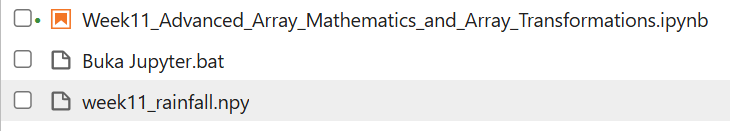

### 3.2.2 Memuat Array dengan `np.load()`

Gunakan **`np.load("nama_file.npy")`** untuk membaca array yang telah disimpan. Pastikan file berada di lokasi yang sesuai dengan *path* yang ditulis (jika hanya nama file, NumPy mencarinya di folder kerja).

Argumen `allow_pickle=False` membatasi agar hanya data numerik biasa yang dimuat, bukan objek Python sembarang — ini praktik yang **lebih aman**.

In [12]:
loaded_rainfall = np.load("week11_rainfall.npy", allow_pickle=False)

print("Loaded rainfall:")
print(loaded_rainfall)
print("Loaded shape:", loaded_rainfall.shape)

Loaded rainfall:
[[12.5  8.   5.5]
 [10.  15.5  7. ]
 [20.  11.   9.5]]
Loaded shape: (3, 3)


### 3.2.3 Menyimpan Array dengan `np.save()`

Format: `np.save("nama_file.npy", array)`. Ekstensi `.npy` akan ditambahkan otomatis jika belum ditulis.

Contoh berikut menyimpan data nilai ujian ke file baru. Gunakan **nama file yang berbeda** agar file sebelumnya tidak tertimpa — `np.save()` akan menimpa file dengan nama yang sama tanpa peringatan.

In [13]:
exam_scores = np.array([[80, 85, 90],
                        [70, 75, 80],
                        [90, 92, 94]])

np.save("week11_exam_scores.npy", exam_scores)
print("Saved file: week11_exam_scores.npy")
print("Saved array:")
print(exam_scores)

Saved file: week11_exam_scores.npy
Saved array:
[[80 85 90]
 [70 75 80]
 [90 92 94]]


### 3.2.4 Memeriksa Array Hasil Pemuatan

Setelah data dimuat, biasakan memeriksa `.shape`, `.ndim`, dan `.dtype` untuk memastikan strukturnya sesuai harapan.

`np.array_equal(a, b)` mengembalikan `True` jika **shape dan seluruh nilai** kedua array sama — cara cepat untuk membuktikan bahwa data tidak berubah setelah disimpan lalu dimuat kembali.

In [14]:
loaded_scores = np.load("week11_exam_scores.npy", allow_pickle=False)

print("Shape:", loaded_scores.shape)
print("Number of dimensions:", loaded_scores.ndim)
print("Data type:", loaded_scores.dtype)
print("First student's scores:", loaded_scores[0, :])
print("Same values and shape:", np.array_equal(exam_scores, loaded_scores))

Shape: (3, 3)
Number of dimensions: 2
Data type: int64
First student's scores: [80 85 90]
Same values and shape: True


**Perbedaan penting:**
- `.npy` mempertahankan shape dan tipe data, tetapi **bukan format tabel** seperti CSV — tidak ada nama kolom dan tidak bisa dibuka langsung di Excel.
- Hanya muat file `.npy` dari **sumber yang terpercaya**, terutama jika berisi array bertipe `object` (yang memerlukan `allow_pickle=True`), karena file seperti itu dapat menjalankan kode berbahaya.

---
## 3.3 Array Gambar dan Transformasinya

### 3.3.1 Memahami Array RGB dan RGBA

Gambar berwarna digital dapat direpresentasikan sebagai **array 3D** dengan shape **`(tinggi, lebar, kanal)`** — sering disingkat **HWC** (*Height, Width, Channels*).

| Format | Jumlah kanal | Isi kanal |
|---|---|---|
| **RGB** | 3 | Red, Green, Blue |
| **RGBA** | 4 | Red, Green, Blue, **Alpha** (transparansi) |

Pada gambar 8-bit, setiap kanal bertipe **`uint8`** (bilangan bulat tak bertanda 8-bit) dengan rentang **0–255**. Contoh: `[255, 0, 0]` = merah murni, `[255, 255, 255]` = putih, `[0, 0, 0]` = hitam.

Pada sel berikut, kanal alpha (`255` = tidak transparan) dibuat dengan `np.full()` lalu ditempelkan ke gambar RGB melalui `np.concatenate(..., axis=2)` sehingga menjadi RGBA.

In [15]:
# Gambar RGB sederhana: 3 baris x 3 kolom x 3 kanal warna
rgb_image = np.array([
    [[255, 0, 0],   [0, 255, 0],   [0, 0, 255]],
    [[255, 255, 0], [0, 255, 255], [255, 0, 255]],
    [[255, 255, 255], [128, 128, 128], [0, 0, 0]]
], dtype=np.uint8)

alpha_channel = np.full((*rgb_image.shape[:2], 1), 255, dtype=np.uint8)
rgba_image = np.concatenate((rgb_image, alpha_channel), axis=2)

print("RGB shape:", rgb_image.shape)
print("RGBA shape:", rgba_image.shape)
print("Top-left RGB pixel:", rgb_image[0, 0])
print("Top-left RGBA pixel:", rgba_image[0, 0])

RGB shape: (3, 3, 3)
RGBA shape: (3, 3, 4)
Top-left RGB pixel: [255   0   0]
Top-left RGBA pixel: [255   0   0 255]


### 3.3.2 Memilih Kanal Warna

| Kode | Kanal | Shape hasil |
|---|---|---|
| `image[:, :, 0]` | Red | `(H, W)` — 2D |
| `image[:, :, 1]` | Green | `(H, W)` — 2D |
| `image[:, :, 2]` | Blue | `(H, W)` — 2D |
| `image[:, :, 0:1]` | Red (dengan slicing) | `(H, W, 1)` — tetap 3D |

Perhatikan perbedaannya: **indexing** satu angka menghilangkan sumbu kanal, sedangkan **slicing** `0:1` mempertahankannya.

In [16]:
red_channel = rgb_image[:, :, 0]
green_channel = rgb_image[:, :, 1]
blue_channel = rgb_image[:, :, 2]

print("Red channel:")
print(red_channel)
print("Green channel:")
print(green_channel)
print("Blue channel:")
print(blue_channel)
print("Red shape:", red_channel.shape)
print("Red shape with 0:1:", rgb_image[:, :, 0:1].shape)

Red channel:
[[255   0   0]
 [255   0 255]
 [255 128   0]]
Green channel:
[[  0 255   0]
 [255 255   0]
 [255 128   0]]
Blue channel:
[[  0   0 255]
 [  0 255 255]
 [255 128   0]]
Red shape: (3, 3)
Red shape with 0:1: (3, 3, 1)


### 3.3.3 Memanipulasi Nilai Piksel

Nilai piksel dapat diubah dengan operasi NumPy, misalnya **menambah kecerahan** atau **menghilangkan satu kanal warna**.

> ⚠️ **Masalah *overflow* pada `uint8`:** tipe ini hanya menampung 0–255. Jika `250 + 40` dihitung dalam `uint8`, hasilnya "berputar" menjadi `34`, bukan 290 atau 255!

Solusinya terdiri dari tiga langkah:
1. `.astype(np.int16)` — ubah ke tipe yang lebih besar agar penjumlahan aman;
2. `np.clip(..., 0, 255)` — batasi hasil ke rentang 0–255 (nilai > 255 menjadi 255);
3. `.astype(np.uint8)` — kembalikan ke tipe gambar semula.

In [17]:
# Gunakan tipe lebih besar untuk menghindari overflow uint8
brightened_image = np.clip(rgb_image.astype(np.int16) + 40, 0, 255).astype(np.uint8)

less_red_image = rgb_image.copy()
less_red_image[:, :, 0] = 0

print("Original pixel [1, 1]:", rgb_image[1, 1])
print("Brighter pixel [1, 1]:", brightened_image[1, 1])
print("Original pixel [0, 0]:", rgb_image[0, 0])
print("Pixel without red [0, 0]:", less_red_image[0, 0])
print("Original image remains:", rgb_image[0, 0])

Original pixel [1, 1]: [  0 255 255]
Brighter pixel [1, 1]: [ 40 255 255]
Original pixel [0, 0]: [255   0   0]
Pixel without red [0, 0]: [0 0 0]
Original image remains: [255   0   0]


### 3.3.4 Membalik Array dengan `np.flip()`

| Argumen | Efek pada gambar HWC |
|---|---|
| `axis=0` | Membalik **atas–bawah** (vertikal) |
| `axis=1` | Membalik **kiri–kanan** (horizontal / efek cermin) |
| `axis=2` | Membalik **urutan kanal** (RGB → BGR) — **bukan** orientasi gambar |

Untuk memudahkan pengamatan, sel berikut hanya menampilkan kanal Red sebelum dan sesudah dibalik.

In [18]:
vertical_flip = np.flip(rgb_image, axis=0)
horizontal_flip = np.flip(rgb_image, axis=1)

print("Original red channel:")
print(rgb_image[:, :, 0])
print("Vertical flip (axis=0):")
print(vertical_flip[:, :, 0])
print("Horizontal flip (axis=1):")
print(horizontal_flip[:, :, 0])
print("Flipped shape:", horizontal_flip.shape)

Original red channel:
[[255   0   0]
 [255   0 255]
 [255 128   0]]
Vertical flip (axis=0):
[[255 128   0]
 [255   0 255]
 [255   0   0]]
Horizontal flip (axis=1):
[[  0   0 255]
 [255   0 255]
 [  0 128 255]]
Flipped shape: (3, 3, 3)


**Visualisasi (Opsional)**

Sel-sel berikut menampilkan gambar sintetis di atas menggunakan pustaka `matplotlib`, tanpa mengunduh file dari internet. `matplotlib` hanya dipakai sebagai alat bantu visual — seluruh transformasinya tetap dilakukan dengan NumPy. Jika `matplotlib` belum terpasang, hapus tanda `#` pada sel pertama dan jalankan.

In [21]:
# Opsional untuk menampilkan gambar pada contoh Section 3:
# %pip install matplotlib

In [23]:
import matplotlib
print("Matplotlib version:", matplotlib.__version__)

Matplotlib version: 3.11.2


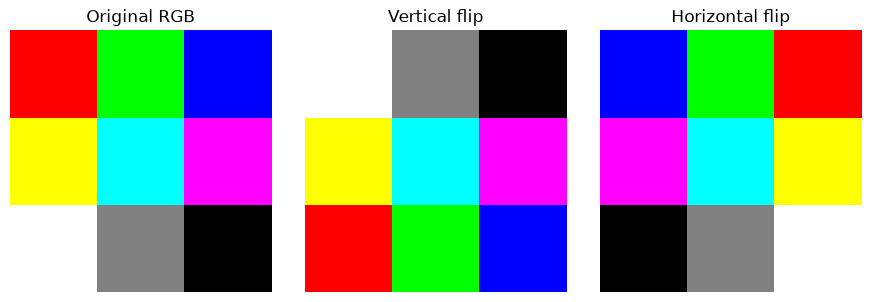

In [24]:
try:
    import matplotlib.pyplot as plt

    figure, axes = plt.subplots(1, 3, figsize=(9, 3))
    for axis, picture, label in zip(
        axes,
        [rgb_image, vertical_flip, horizontal_flip],
        ["Original RGB", "Vertical flip", "Horizontal flip"]
    ):
        axis.imshow(picture)
        axis.set_title(label)
        axis.axis("off")
    plt.tight_layout()
    plt.show()
except ImportError:
    print("Matplotlib belum terpasang. instal matplotlib.")

---
## 3.4 Transposisi Array

### 3.4.1 Transposisi Array

**Transposisi** menukar susunan sumbu array. Untuk matriks 2D, `.T` atau `np.transpose()` mengubah **baris menjadi kolom** dan sebaliknya: shape `(baris, kolom)` → `(kolom, baris)`.

Pada array 1D, `.T` **tidak** mengubah apa pun karena hanya ada satu sumbu. Untuk mengubah vektor menjadi kolom, gunakan `reshape(-1, 1)`.

In [25]:
data_matrix = np.array([[1, 2, 3],
                        [4, 5, 6]])

print("Original:")
print(data_matrix)
print("Shape:", data_matrix.shape)
print("Transposed:")
print(data_matrix.T)
print("Transposed shape:", np.transpose(data_matrix).shape)
print("1D transpose shape:", np.array([1, 2, 3]).T.shape)

Original:
[[1 2 3]
 [4 5 6]]
Shape: (2, 3)
Transposed:
[[1 4]
 [2 5]
 [3 6]]
Transposed shape: (3, 2)
1D transpose shape: (3,)


### 3.4.2 Transposisi Berdasarkan Sumbu

Untuk array 3D atau lebih, `np.transpose(array, axes=(...))` menentukan **urutan baru seluruh sumbu**.

Contoh: `data_3d` berbentuk `(2, 3, 4)` dengan sumbu `(0, 1, 2)`. Jika `axes=(1, 0, 2)`:
- sumbu baru ke-0 = sumbu lama ke-1 (ukuran 3);
- sumbu baru ke-1 = sumbu lama ke-0 (ukuran 2);
- sumbu baru ke-2 = sumbu lama ke-2 (ukuran 4);
- shape hasil: **`(3, 2, 4)`**.

Akibatnya, elemen pada posisi `[i, j, k]` di array asli berpindah ke posisi `[j, i, k]` — perhatikan bagian *ELEMENT COMPARISON* pada keluaran.

`np.swapaxes(array, a, b)` adalah jalan pintas jika **hanya dua sumbu** yang ingin ditukar. Pada contoh ini, `np.swapaxes(data_3d, 0, 1)` memberikan hasil yang sama dengan `np.transpose(data_3d, axes=(1, 0, 2))`.

> 💡 Penerapan umum: mengubah gambar dari format **HWC** `(H, W, C)` menjadi **CHW** `(C, H, W)` yang dibutuhkan beberapa pustaka *deep learning*, yaitu dengan `np.transpose(image, (2, 0, 1))`.

In [28]:
data_3d = np.arange(24).reshape(2, 3, 4)
reordered = np.transpose(data_3d, axes=(1, 0, 2))

print("=== ORIGINAL ARRAY ===")
print("Shape:", data_3d.shape)
print(data_3d)

print("\nLayer 0:")
print(data_3d[0])

print("\nLayer 1:")
print(data_3d[1])

print("\n=== TRANSPOSED ARRAY ===")
print("Shape:", reordered.shape)
print(reordered)

print("\nLayer 0:")
print(reordered[0])

print("\nLayer 1:")
print(reordered[1])

print("\nLayer 2:")
print(reordered[2])

print("\n=== ELEMENT COMPARISON ===")
print("Original [1, 2, 3]:", data_3d[1, 2, 3])
print("Transposed [2, 1, 3]:", reordered[2, 1, 3])

print("\n=== SWAPAXES ===")
print(np.swapaxes(data_3d, 0, 1))

=== ORIGINAL ARRAY ===
Shape: (2, 3, 4)
[[[ 0  1  2  3]
  [ 4  5  6  7]
  [ 8  9 10 11]]

 [[12 13 14 15]
  [16 17 18 19]
  [20 21 22 23]]]

Layer 0:
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

Layer 1:
[[12 13 14 15]
 [16 17 18 19]
 [20 21 22 23]]

=== TRANSPOSED ARRAY ===
Shape: (3, 2, 4)
[[[ 0  1  2  3]
  [12 13 14 15]]

 [[ 4  5  6  7]
  [16 17 18 19]]

 [[ 8  9 10 11]
  [20 21 22 23]]]

Layer 0:
[[ 0  1  2  3]
 [12 13 14 15]]

Layer 1:
[[ 4  5  6  7]
 [16 17 18 19]]

Layer 2:
[[ 8  9 10 11]
 [20 21 22 23]]

=== ELEMENT COMPARISON ===
Original [1, 2, 3]: 23
Transposed [2, 1, 3]: 23

=== SWAPAXES ===
[[[ 0  1  2  3]
  [12 13 14 15]]

 [[ 4  5  6  7]
  [16 17 18 19]]

 [[ 8  9 10 11]
  [20 21 22 23]]]


---
## 3.5 Menumpuk dan Membagi Array

### 3.5.1 Membagi Array dengan `np.split()`

**Splitting** membagi satu array menjadi beberapa bagian.

| Fungsi | Syarat | Contoh |
|---|---|---|
| `np.split(arr, n)` | Panjang sumbu **harus habis dibagi** `n` | 6 elemen → 2 bagian @3 ✅; 7 elemen → 3 bagian ❌ |
| `np.array_split(arr, n)` | Boleh tidak habis dibagi; bagian awal mendapat sisa | 7 elemen → 3 bagian: 3, 2, 2 ✅ |

Argumen `axis` menentukan arah pembagian: `axis=0` membagi menurut baris, `axis=1` menurut kolom.

In [29]:
monthly_values = np.array([10, 12, 15, 18, 20, 22])
first_half, second_half = np.split(monthly_values, 2)

print("First half:", first_half)
print("Second half:", second_half)

measurement_table = np.arange(1, 13).reshape(3, 4)
left_part, right_part = np.split(measurement_table, 2, axis=1)

print("Original table:")
print(measurement_table)
print("Left half shape:", left_part.shape)
print(left_part)
print("Right half shape:", right_part.shape)
print(right_part)
print("Unequal split example:", [part.tolist() for part in np.array_split(np.arange(7), 3)])

First half: [10 12 15]
Second half: [18 20 22]
Original table:
[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
Left half shape: (3, 2)
[[ 1  2]
 [ 5  6]
 [ 9 10]]
Right half shape: (3, 2)
[[ 3  4]
 [ 7  8]
 [11 12]]
Unequal split example: [[0, 1, 2], [3, 4], [5, 6]]


**Penjelasan baris terakhir sel di atas:**
1. `np.arange(7)` membuat array `[0, 1, 2, 3, 4, 5, 6]`.
2. `np.array_split(..., 3)` membaginya menjadi **3 bagian** berisi **3, 2, dan 2** elemen.
3. `[part.tolist() for part in ...]` adalah *list comprehension*: setiap bagian diambil lalu diubah menjadi list Python dengan `.tolist()` agar tampilannya rapi.
4. Hasil akhir: `[[0, 1, 2], [3, 4], [5, 6]]`.

### 3.5.2 Menumpuk Array dengan `np.stack()`

**Stacking** menyatukan beberapa array yang **shape-nya sama persis** dengan **membuat sumbu baru**.

Dua vektor berbentuk `(3,)`:
- `np.stack(..., axis=0)` → `(2, 3)`: setiap vektor menjadi satu **baris**;
- `np.stack(..., axis=1)` → `(3, 2)`: setiap vektor menjadi satu **kolom**.

**Perbedaan `np.stack()` dan `np.concatenate()`:**

| Fungsi | Jumlah dimensi hasil | Contoh: dua array `(3,)` |
|---|---|---|
| `np.stack()` | **Bertambah 1** (sumbu baru) | `(2, 3)` |
| `np.concatenate()` | **Tetap** (menyambung sumbu yang ada) | `(6,)` |

Cara cepat mengeceknya: hitung jumlah tanda kurung siku pembuka sebelum dan sesudah operasi.

In [31]:
day_one = np.array([12, 15, 18])
day_two = np.array([10, 17, 20])

stacked_rows = np.stack((day_one, day_two), axis=0)
stacked_columns = np.stack((day_one, day_two), axis=1)

print("Original vector shape:", day_one.shape)
print("Stacked by rows:")
print(stacked_rows)
print("Shape:", stacked_rows.shape)
print("Stacked by columns:")
print(stacked_columns)
print("Shape:", stacked_columns.shape)

Original vector shape: (3,)
Stacked by rows:
[[12 15 18]
 [10 17 20]]
Shape: (2, 3)
Stacked by columns:
[[12 10]
 [15 17]
 [18 20]]
Shape: (3, 2)


### 3.5.3 Mengubah Bentuk Hasil Pembagian

Bagian ini menggabungkan beberapa konsep sekaligus:
1. `np.split(measurement_table, 2, axis=1)` → tabel `(3, 4)` dibagi menjadi dua blok berbentuk `(3, 2)`.
2. `.reshape(-1)` → setiap blok (6 elemen) diratakan menjadi vektor 1D `(6,)`. Hasilnya setara dengan `.flatten()`.
3. `np.stack(..., axis=0)` → dua vektor `(6,)` ditumpuk menjadi array 2D **`(2, 6)`**.

In [32]:
first_block, second_block = np.split(measurement_table, 2, axis=1)
first_vector = first_block.reshape(-1)
second_vector = second_block.reshape(-1)
reshaped_and_stacked = np.stack((first_vector, second_vector), axis=0)

print("Shape of each split block:", first_block.shape)
print("Shape after reshape:", first_vector.shape)
print("Reshaped and stacked:")
print(reshaped_and_stacked)
print("New shape:", reshaped_and_stacked.shape)

Shape of each split block: (3, 2)
Shape after reshape: (6,)
Reshaped and stacked:
[[ 1  2  5  6  9 10]
 [ 3  4  7  8 11 12]]
New shape: (2, 6)


---
## 3.6 Latihan Mandiri

Kerjakan menggunakan **NumPy**. Tambahkan sel kode di bawah setiap latihan untuk menulis dan menguji jawaban. **Kunci jawaban tidak disediakan** agar Anda berlatih secara mandiri.

### Latihan 1 — Broadcasting

Gunakan matriks berikut:

```python
scores = np.array([[70, 80, 90],
                   [75, 85, 95],
                   [60, 70, 80]])
```

1. Tambahkan bonus `[5, 3, 2]` pada **setiap kolom** menggunakan broadcasting.
2. Tambahkan bonus `[1, 4, 2]` pada **setiap baris** dengan `reshape(-1, 1)`.
3. Hitung rata-rata masing-masing kolom dengan `keepdims=True`, lalu kurangkan dari `scores`.
4. Tampilkan `.shape` setiap array bonus dan hasil perhitungan.

### Latihan 2 — Menyimpan dan Memuat Array

Gunakan `temperatures = np.array([[29, 31, 30], [28, 32, 33], [27, 30, 31]])`.

1. Simpan array ke file `week11_temperatures.npy` menggunakan `np.save()`.
2. Muat kembali dengan `np.load()` dan simpan ke variabel baru.
3. Periksa `.shape`, `.ndim`, dan `.dtype` dari hasil pemuatan.
4. Gunakan `np.array_equal()` untuk memeriksa kesamaan array asli dan hasil pemuatan.

### Latihan 3 — Array Gambar dan Transformasi

Gunakan gambar RGB berikut:

```python
image = np.array([[[255, 0, 0], [0, 255, 0]],
                  [[0, 0, 255], [255, 255, 255]]], dtype=np.uint8)
```

1. Tampilkan shape gambar serta matriks kanal Red, Green, dan Blue.
2. Buat salinan gambar lalu ubah seluruh nilai kanal Blue menjadi 0.
3. Tambahkan kecerahan 30 pada semua kanal dengan `astype()`, `np.clip()`, lalu `astype(np.uint8)`.
4. Balik gambar secara horizontal dan vertikal menggunakan `np.flip()`, lalu periksa piksel pada posisi `[0, 0]` di setiap hasil.

### Latihan 4 — Transposisi Array

Gunakan `arr = np.arange(24).reshape(2, 3, 4)`.

1. Periksa `.shape` array awal.
2. Gunakan `np.transpose()` untuk mengubah urutan sumbu menjadi `(1, 0, 2)`.
3. Gunakan `np.swapaxes()` untuk menghasilkan bentuk array yang sama.
4. Buat gambar `image = np.zeros((4, 5, 3))`, ubah dari format HWC menjadi CHW, lalu kembalikan lagi ke HWC.

### Latihan 5 — Menumpuk dan Membagi Array

Gunakan `data = np.arange(1, 13).reshape(3, 4)`.

1. Bagi `data` menjadi dua bagian menurut kolom menggunakan `np.split()`.
2. Periksa bentuk masing-masing bagian, lalu ubah menjadi vektor 1D dengan `reshape(-1)`.
3. Gabungkan kedua vektor memakai `np.stack(axis=0)` dan periksa bentuknya.
4. Gunakan `np.array_split()` untuk membagi `np.arange(10)` menjadi tiga bagian; bandingkan ukuran setiap bagian.

### Latihan 6 — Praktik Statistik Terpadu

Gunakan data intensitas curah hujan (baris = hari, kolom = lokasi):

```python
rainfall = np.array([[12, 8, 5],
                     [10, 15, 7],
                     [20, 11, 9],
                     [8, 6, 4]])
```

1. Hitung rata-rata tiap lokasi, lalu lakukan **centering** menggunakan broadcasting.
2. Simpan hasil centering ke file `week11_centered_rainfall.npy`, kemudian muat kembali.
3. Ubah susunan data hasil pemuatan dari `(hari, lokasi)` menjadi `(lokasi, hari)` dengan `.T`.
4. Bagi data hasil transposisi menjadi dua bagian menurut kolom menggunakan `np.split()`.
5. Gabungkan kembali kedua bagian dengan `np.concatenate(axis=1)` dan buktikan hasilnya sama dengan data sebelum dibagi.

---
## 3.7 Ringkasan dan Evaluasi Diri — Bagian III

### Konsep Penting

- **Broadcasting** memungkinkan operasi antar-array dengan shape berbeda jika setiap dimensi (dibandingkan dari kanan) sama atau salah satunya 1.
- **`reshape(-1, 1)`** membentuk vektor kolom; **`keepdims=True`** mempertahankan dimensi agar siap di-broadcast.
- **`np.save()`** menyimpan satu array ke file **`.npy`**; **`np.load()`** membacanya kembali lengkap dengan `shape` dan `dtype`.
- **RGB** memiliki tiga kanal dan **RGBA** empat kanal; shape gambar lazimnya `(tinggi, lebar, kanal)` atau HWC.
- **`image[:, :, k]`** mengambil satu kanal warna; **`np.clip()`** membatasi nilai piksel agar tidak keluar dari rentang yang diinginkan.
- **`np.flip(axis=0)`** membalik atas–bawah; **`np.flip(axis=1)`** membalik kiri–kanan.
- **`.T`** mentransposisi array; **`np.transpose(..., axes=...)`** mengatur ulang seluruh sumbu secara eksplisit, termasuk HWC → CHW; **`np.swapaxes()`** menukar dua sumbu.
- **`np.split()`** membagi array menjadi bagian sama besar; **`np.array_split()`** mengizinkan ukuran tidak sama.
- **`np.stack()`** menambah sumbu baru, sedangkan **`np.concatenate()`** menyambung pada sumbu yang sudah ada.

### Evaluasi Diri Singkat

Coba jawab tanpa menjalankan kode:

1. Apa shape hasil penjumlahan array `(3, 1)` dan `(1, 4)` dengan broadcasting?
2. Apakah array berbentuk `(2, 3)` dapat langsung dijumlahkan dengan vektor `(2,)`?
3. Fungsi apa yang digunakan untuk menyimpan dan membuka kembali array `.npy`?
4. Berapa jumlah kanal dan shape array untuk gambar RGBA dengan tinggi 5 dan lebar 4?
5. Sumbu berapa yang digunakan `np.flip()` untuk membalik gambar kiri–kanan pada format HWC?
6. Apa shape hasil `np.transpose(np.zeros((4, 5, 3)), (2, 0, 1))`?
7. Apa shape hasil `np.stack((np.ones(3), np.zeros(3)), axis=0)`?
8. Apa perbedaan utama `np.stack()` dan `np.concatenate()`?

<details>
<summary><b>Klik untuk melihat jawaban</b></summary>

1. `(3, 4)`.
2. Tidak — dimensi paling kanan adalah 3 dan 2, yang tidak sama dan tidak ada yang bernilai 1.
3. `np.save()` dan `np.load()`.
4. 4 kanal; shape `(5, 4, 4)`.
5. `axis=1`.
6. `(3, 4, 5)`.
7. `(2, 3)`.
8. `np.stack()` menambah sumbu baru, sedangkan `np.concatenate()` menyambung pada sumbu yang sudah ada.
</details>

### Sumber Materi

- [NumPy: The Absolute Basics for Beginners — NumPy Documentation](https://numpy.org/doc/stable/user/absolute_beginners.html)
- [Broadcasting — NumPy Documentation](https://numpy.org/doc/stable/user/basics.broadcasting.html)
- [NumPy `save` — NumPy Documentation](https://numpy.org/doc/stable/reference/generated/numpy.save.html)
- [NumPy `load` — NumPy Documentation](https://numpy.org/doc/stable/reference/generated/numpy.load.html)
- [NumPy `flip` — NumPy Documentation](https://numpy.org/doc/stable/reference/generated/numpy.flip.html)
- [NumPy `transpose` — NumPy Documentation](https://numpy.org/doc/stable/reference/generated/numpy.transpose.html)
- [NumPy `split` — NumPy Documentation](https://numpy.org/doc/stable/reference/generated/numpy.split.html)
- [NumPy `stack` — NumPy Documentation](https://numpy.org/doc/stable/reference/generated/numpy.stack.html)
- [Introduction to NumPy — DataCamp](https://www.datacamp.com/courses/introduction-to-numpy)